# Solving the n-Queens Problem using Local Search — Lab03 Bài 2–4

**Sinh viên thực hiện:** Nguyễn Hữu Tri — MSSV 3123410387.

**Phạm vi độc lập:** Bài 2 mô hình hóa; Bài 3 Task 1–3; Bài 4 Task 4–5.
Không dùng `n_queens_sa.py` hoặc thuật toán cài sẵn từ bên ngoài. Task 6/Bài 8 và phần bonus vẫn giữ nguyên placeholder của giảng viên, ngoài phạm vi phần việc của Tri.

**Sử dụng AI:** ChatGPT hỗ trợ phân tích đề, viết và kiểm thử code, thiết kế thực nghiệm, review notebook. Người nộp cần đọc, hiểu và xác nhận lại nội dung theo yêu cầu môn học.

## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# Notebook dùng các file/thư viện cục bộ, không mount Google Drive, không đổi cwd.
from pathlib import Path
print('Working directory:', Path.cwd().name)

Working directory: lab03 - local search


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


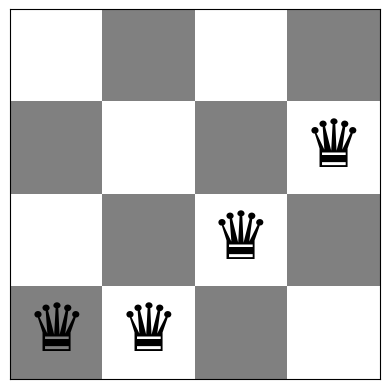

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


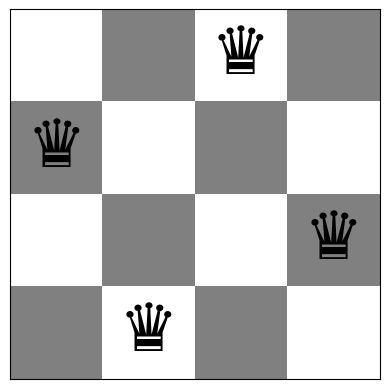

In [4]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## 4. Quan sát bàn cờ ngẫu nhiên với $n=4$ và $n=8$

Giữ `seed=1234` theo code mẫu để hai lần chạy notebook cho **cùng** ví dụ. Kết quả in dưới hình cho biết vector trạng thái và số xung đột. **Một trạng thái ngẫu nhiên không đại diện cho tỷ lệ thành công**; phần 8 sẽ chạy nhiều trạng thái để khảo sát.


Bàn cờ ngẫu nhiên n=4: [3, 3, 2, 1], conflicts=4
Board with 4 conflicts.


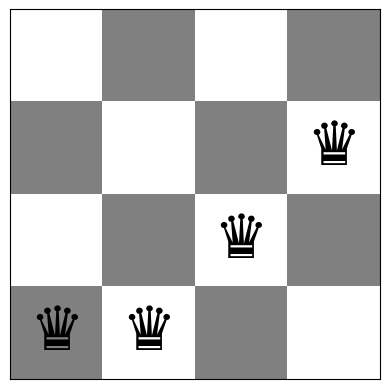


Bàn cờ ngẫu nhiên n=8: [4, 4, 0, 1, 7, 1, 7, 1], conflicts=8
Board with 8 conflicts.


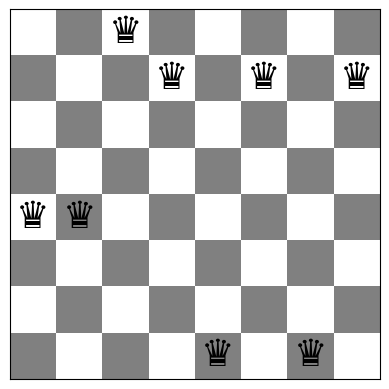

In [5]:
np.random.seed(1234)  # hàm random_board() của notebook mẫu dùng bộ sinh ngẫu nhiên NumPy toàn cục
board4 = random_board(4)
board8 = random_board(8)
for n, q in [(4, board4), (8, board8)]:
    print(f'\nBàn cờ ngẫu nhiên n={n}: {q.tolist()}, conflicts={conflicts(q)}')
    show_board(q, fontsize=44 if n == 4 else 27)

## 5. Đối chiếu với một cấu hình không xung đột

Đề yêu cầu so sánh với `board = [1, 3, 0, 2]` cho $n=4$; vector này là một nghiệm với 4 hậu. Bổ sung một nghiệm 8 hậu chỉ để xác nhận cùng một biểu diễn và hàm mục tiêu vẫn hoạt động trên $n=8$, không phải kết quả chạy thuật toán tìm kiếm.


Cấu hình đã biết n=4: [1, 3, 0, 2], conflicts=0
Board with 0 conflicts.


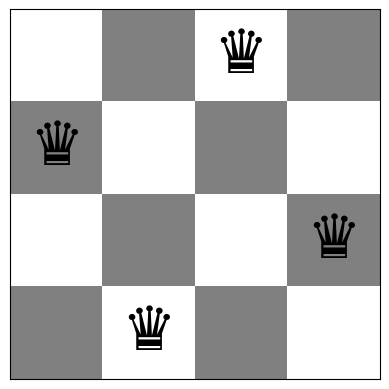


Cấu hình đã biết n=8: [0, 4, 7, 5, 2, 6, 1, 3], conflicts=0
Board with 0 conflicts.


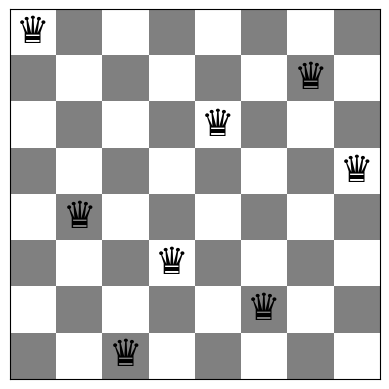

In [6]:
solution4 = np.array([1, 3, 0, 2], dtype=int)
solution8 = np.array([0, 4, 7, 5, 2, 6, 1, 3], dtype=int)
assert conflicts(solution4) == 0
assert conflicts(solution8) == 0
for n, q in [(4, solution4), (8, solution8)]:
    print(f'\nCấu hình đã biết n={n}: {q.tolist()}, conflicts={conflicts(q)}')
    show_board(q, fontsize=44 if n == 4 else 27)

## 6. Kích thước không gian tìm kiếm và số trạng thái láng giềng

Trong biểu diễn “một hậu trên mỗi cột”, **không được** tự ý hạn chế mỗi hàng một hậu trước khi sinh lân cận. Nếu chỉ cho các vector hoán vị, toán tử “đổi một hậu sang hàng khác trong cùng cột” có thể phá tính chất hoán vị, khiến định nghĩa bài toán không nhất quán.

| Đại lượng | Công thức | $n=4$ | $n=8$ |
|---|---:|---:|---:|
| Số trạng thái | $n^n$ | 256 | 16.777.216 |
| Số trạng thái lân cận | $n(n-1)$ | 12 | 56 |
| Số hoán vị hàng (chỉ là một tập con) | $n!$ | 24 | 40.320 |

Hàm `neighbors()` dưới đây dùng **phép gán sang hàng khác cùng cột**; trả về `(column, new_row, new_board)` để dễ kiểm tra nguồn gốc nước đi. Đây mới là **mô hình toán tử**, chưa phải thuật toán chọn bước đi Hill Climbing.

In [7]:
from math import factorial
import pandas as pd

def neighbors(board):
    """Sinh toàn bộ láng giềng hợp lệ: đổi một hậu sang hàng khác trong cùng cột."""
    q = np.asarray(board, dtype=int)
    n = len(q)
    if q.ndim != 1 or n < 1 or np.any((q < 0) | (q >= n)):
        raise ValueError('board phải là vector n phần tử, mỗi hàng thuộc [0, n-1].')
    for column in range(n):
        for new_row in range(n):
            if new_row == q[column]:
                continue
            candidate = q.copy()  # không chỉnh sửa trạng thái gốc
            candidate[column] = new_row
            yield (column, new_row, candidate)

space_table = pd.DataFrame([
    {'n': n, 'n^n (trạng thái)': n**n, 'n! (hoán vị)': factorial(n),
     'n(n−1) (lân cận)': n*(n-1)} for n in [4, 8]
])
display(space_table)
for n, q in [(4, board4), (8, board8)]:
    candidates = list(neighbors(q))
    print(f'n={n}: đếm được {len(candidates)} láng giềng; lý thuyết {n*(n-1)}')
    assert len(candidates) == n*(n-1)

,n,n^n (trạng thái),n! (hoán vị),n(n−1) (lân cận)
0,4,256,24,12
1,8,16777216,40320,56


n=4: đếm được 12 láng giềng; lý thuyết 12
n=8: đếm được 56 láng giềng; lý thuyết 56


## 7. Minh họa lân cận và chất lượng nước đi

Từ một bàn cờ ngẫu nhiên, có thể có nước đi làm **giảm**, **giữ nguyên** hoặc **tăng** số xung đột. Bài 2 mới nhận diện các nước đi; đến Bài 3, thuật toán Hill Climbing mới sử dụng hàm $f$ để quyết định chọn nước đi nào.

In [8]:
rows = []
for n, q in [(4, board4), (8, board8)]:
    base_f = conflicts(q)
    local_moves = list(neighbors(q))
    scores = np.array([conflicts(candidate) for _, _, candidate in local_moves])
    rows.append({'n': n, 'f(trạng thái gốc)': base_f,
                 'Cải thiện (Δ<0)': int((scores < base_f).sum()),
                 'Ngang (Δ=0)': int((scores == base_f).sum()),
                 'Xấu hơn (Δ>0)': int((scores > base_f).sum()),
                 'Tổng láng giềng': len(local_moves)})
neighbor_table = pd.DataFrame(rows)
display(neighbor_table)

print('Ví dụ 5 láng giềng đầu của bàn cờ n=4:')
for column, row, q in list(neighbors(board4))[:5]:
    print(f'Đổi cột {column} sang hàng {row}: {q.tolist()}, conflicts={conflicts(q)}')

,n,f(trạng thái gốc),Cải thiện (Δ<0),Ngang (Δ=0),Xấu hơn (Δ>0),Tổng láng giềng
0,4,4,6,4,2,12
1,8,8,25,11,20,56


Ví dụ 5 láng giềng đầu của bàn cờ n=4:
Đổi cột 0 sang hàng 0: [0, 3, 2, 1], conflicts=4
Đổi cột 0 sang hàng 1: [1, 3, 2, 1], conflicts=4
Đổi cột 0 sang hàng 2: [2, 3, 2, 1], conflicts=5
Đổi cột 1 sang hàng 0: [3, 0, 2, 1], conflicts=1
Đổi cột 1 sang hàng 1: [3, 1, 2, 1], conflicts=3


## 8. Kiểm chứng độc lập của hàm `conflicts()` và toán tử lân cận

Để tránh trường hợp hai hàm cùng mắc một lỗi, `conflicts_reference()` dưới đây dùng **duyệt từng cặp hậu**, khác với cách đếm bộ đếm của notebook gốc. Kiểm tra:

- Các cấu hình có giá trị xung đột đã biết.
- **Vét cạn tất cả 256 trạng thái n=4**, so sánh hai cách đếm và xác định có bao nhiêu nghiệm.
- Thử thêm 1.000 trạng thái n=8 với seed cố định.
- Xác minh mỗi láng giềng khác trạng thái gốc ở **chính xác một cột**, không thay đổi board ban đầu và không trùng lặp.

In [9]:
from itertools import product

def conflicts_reference(board):
    q = np.asarray(board)
    n = len(q)
    return sum(int(q[i] == q[j] or abs(int(q[i]) - int(q[j])) == j - i)
               for i in range(n) for j in range(i + 1, n))

known_cases = [([1, 3, 0, 2], 0), ([0, 0, 0, 0], 6),
               ([0, 1, 2, 3], 6), ([0, 4, 7, 5, 2, 6, 1, 3], 0)]
for q, expected in known_cases:
    assert conflicts(q) == conflicts_reference(q) == expected

solutions4 = []
for positions in product(range(4), repeat=4):
    assert conflicts(positions) == conflicts_reference(positions)
    if conflicts(positions) == 0:
        solutions4.append(positions)
assert set(solutions4) == {(1, 3, 0, 2), (2, 0, 3, 1)}

rng_check = np.random.default_rng(20261016)
for _ in range(1000):
    q = rng_check.integers(0, 8, size=8)
    assert conflicts(q) == conflicts_reference(q)

for n, start in [(4, board4), (8, board8)]:
    initial = np.array(start, copy=True)
    moves = list(neighbors(initial))
    different = {tuple(candidate) for _, _, candidate in moves}
    assert len(moves) == len(different) == n*(n-1)
    assert all(np.count_nonzero(candidate != initial) == 1 for _, _, candidate in moves)
    assert all(np.all((candidate >= 0) & (candidate < n)) for _, _, candidate in moves)
    assert np.array_equal(initial, start)

print('PASS: đối chiếu 256/256 bàn cờ n=4 và 1000/1000 bàn cờ n=8.')
print('PASS: số láng giềng, không trùng lặp, đúng một cột thay đổi, giữ nguyên board gốc.')
print('Hai nghiệm n=4 tìm bằng vét cạn:', solutions4)

PASS: đối chiếu 256/256 bàn cờ n=4 và 1000/1000 bàn cờ n=8.
PASS: số láng giềng, không trùng lặp, đúng một cột thay đổi, giữ nguyên board gốc.
Hai nghiệm n=4 tìm bằng vét cạn: [(1, 3, 0, 2), (2, 0, 3, 1)]


## 9. Khảo sát mở rộng: phân phối xung đột của bàn cờ ngẫu nhiên

Để đánh giá **trạng thái khởi tạo**, lấy 1.000 board ngẫu nhiên cho mỗi $n=4$ và $n=8$ bằng `np.random.default_rng` với các seed độc lập. Đếm số xung đột và tỷ lệ tình cờ tạo được $f=0$.

Thử nghiệm này **không đo hiệu quả Hill Climbing** (vì chưa chạy thuật toán tìm kiếm). Với 1.000 lượt, n=8 có thể không có nghiệm ngẫu nhiên; số lần bằng 0 trong mẫu **không chứng minh xác suất lý thuyết bằng 0**.

In [10]:
random_samples = {}
record = []
for n in (4, 8):
    rng = np.random.default_rng(20261016 + n)
    samples = np.array([conflicts(rng.integers(0, n, size=n)) for _ in range(1000)])
    random_samples[n] = samples
    record.append({'n': n, 'Số lần': len(samples), 'f trung bình': round(float(samples.mean()), 3),
                   'f nhỏ nhất': int(samples.min()), 'f lớn nhất': int(samples.max()),
                   'Số lần f=0': int((samples == 0).sum()),
                   'Tỷ lệ f=0 (%)': round(100 * float((samples == 0).mean()), 2)})
random_table = pd.DataFrame(record)
display(random_table)

,n,Số lần,f trung bình,f nhỏ nhất,f lớn nhất,Số lần f=0,Tỷ lệ f=0 (%)
0,4,1000,3.250,0,6,13,1.3
1,8,1000,7.859,2,16,0,0.0


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


...

findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


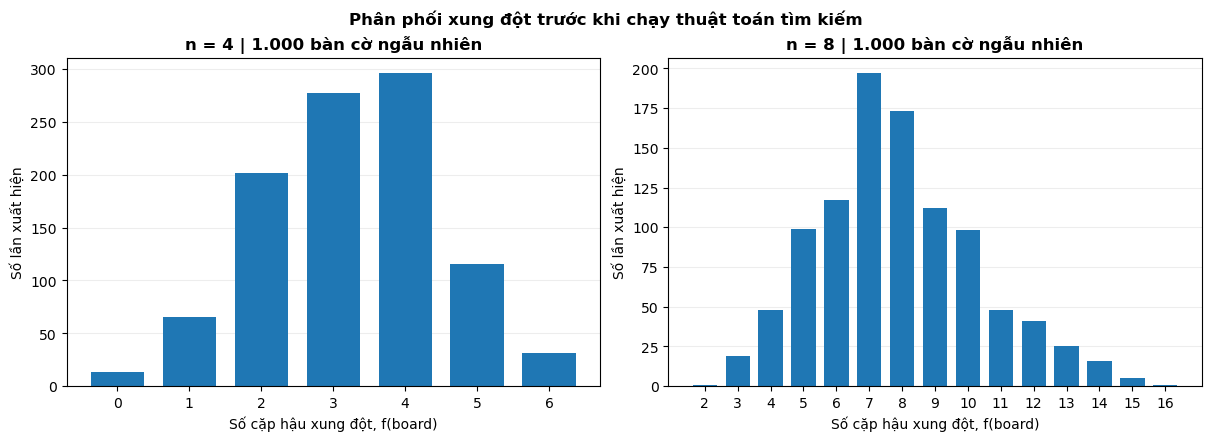

In [11]:
# Hình thực nghiệm: biểu đồ tần suất giá trị f của 1.000 board ngẫu nhiên.
plt.rcParams['font.family'] = 'Noto Sans Display'
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout='constrained')
for ax, n in zip(axes, (4, 8)):
    samples = random_samples[n]
    levels, counts = np.unique(samples, return_counts=True)
    ax.bar(levels, counts, width=0.74)
    ax.set_title(f'n = {n} | 1.000 bàn cờ ngẫu nhiên', weight='bold')
    ax.set_xlabel('Số cặp hậu xung đột, f(board)')
    ax.set_ylabel('Số lần xuất hiện')
    ax.set_xticks(levels)
    ax.grid(axis='y', alpha=0.22)
    ax.set_axisbelow(True)
plt.suptitle('Phân phối xung đột trước khi chạy thuật toán tìm kiếm', fontsize=12, weight='bold')
plt.show()

## 10. Nhận xét và kết luận Bài 2

**(1) Biểu diễn trạng thái.** Vector $q$ có đúng một phần tử cho mỗi cột, nên không cần kiểm tra xung đột theo cột. Hai hậu vẫn có thể trùng hàng hoặc đường chéo, vì vậy không nên giới hạn vector thành hoán vị trước khi tìm kiếm.

**(2) Hàm mục tiêu.** `conflicts()` đếm **cặp** tấn công nhau: bằng 0 là nghiệm hợp lệ, dương là cấu hình cần cải thiện. Kiểm chứng độc lập xác nhận hàm gốc khớp cách đếm từng cặp trên mọi board n=4 và 1.000 board n=8.

**(3) Toán tử lân cận.** Mỗi nước đi đổi hàng cho **chính xác một quân** nhưng giữ nguyên cột. Điều đó tạo $n(n-1)$ láng giềng: 12 khi $n=4$, 56 khi $n=8$. Bài 3 sẽ áp dụng các chính sách **chọn** lân cận, còn Bài 2 chỉ mô hình hóa và kiểm tra chúng.

**(4) Minh họa nghiệm.** `[1,3,0,2]` là nghiệm $n=4$ với $f=0$; vét cạn 256 trạng thái cho đúng hai nghiệm trong cách biểu diễn đang xét. Vì vậy xác suất chính xác khi chọn đều ngẫu nhiên một vector n=4 là $2/256=0{,}78125\%$. Trong 1.000 lần thử bên trên, tỷ lệ mẫu 1,3% có thể lệch do dao động thống kê; **không** thể coi đây là sự cải thiện do thuật toán tìm kiếm (vì chưa có thuật toán tìm kiếm nào được chạy).

**(5) Giới hạn và bước tiếp theo.** Không thể đánh giá Hill Climbing tốt hay kém chỉ từ số xung đột của trạng thái ban đầu; cần triển khai và đo các thuật toán Bài 3–4 với nhiều seed, cùng điều kiện dừng và cùng hàm mục tiêu.

**Kiểm tra ngoại lệ từ notebook mẫu:** Không tồn tại nghiệm $f=0$ cho $n=2,3$. Nhận định “mọi $n$ có nghiệm” trong phần giới thiệu của notebook chỉ đúng với $n=1$ hoặc $n\ge4$. Điều này không ảnh hưởng hai kích thước $n=4,8$ được yêu cầu trong lab.

In [12]:
# Kiểm chứng nhỏ cho lưu ý về n=2 và n=3 trong đoạn nhận xét.
for n in (2, 3):
    best = min(conflicts(board) for board in product(range(n), repeat=n))
    assert best > 0
    print(f'n={n}: f nhỏ nhất khi vét cạn = {best} (>0, không có nghiệm).')
print('HOÀN THÀNH BÀI 2 — toàn bộ kiểm thử đều đạt.')

n=2: f nhỏ nhất khi vét cạn = 1 (>0, không có nghiệm).
n=3: f nhỏ nhất khi vét cạn = 1 (>0, không có nghiệm).
HOÀN THÀNH BÀI 2 — toàn bộ kiểm thử đều đạt.


## Phần bổ sung: Bài 3 – Task 1–3 (Hill Climbing)

### Bài 3 — Các tiện ích dùng chung cho ba thuật toán Hill Climbing

Định nghĩa lân cận hợp lệ, kiểm tra đầu vào, seed và định dạng kết quả; các đoạn code dưới đây **do Tri cài độc lập**.

In [13]:
import math
from time import perf_counter
import pandas as pd
from IPython.display import display


def check_board(board):
    """Không chấp nhận bàn cờ sai kích thước/chỉ số hàng; không sửa đầu vào."""
    q = np.asarray(board)
    if q.ndim != 1 or len(q) < 2 or q.dtype.kind not in 'iu':
        raise ValueError('board phải là vector số nguyên, n >= 2.')
    n = len(q)
    if np.any((q < 0) | (q >= n)):
        raise ValueError('Mỗi phần tử phải thuộc [0, n-1].')
    return np.array(q, dtype=int, copy=True)


def local_neighbors(board, operator='any'):
    """Sinh toàn bộ láng giềng khác nhau; hỗ trợ operator='any' (chuẩn n*(n-1)) hoặc 'adjacent' (n..2n)."""
    q = check_board(board)
    n = len(q)
    for col in range(n):
        if operator == 'adjacent':
            candidate_rows = [row for row in (q[col] - 1, q[col] + 1) if 0 <= row < n]
        else:
            candidate_rows = [row for row in range(n) if row != q[col]]
        for row in candidate_rows:
            candidate = q.copy()
            candidate[col] = row
            yield candidate


def random_neighbor(board, rng, operator='any'):
    """Lấy đều một láng giềng; hỗ trợ operator='any' hoặc 'adjacent'."""
    q = np.array(board, copy=True)
    n = len(q)
    col = int(rng.integers(n))
    if operator == 'adjacent':
        moves = [r for r in (q[col] - 1, q[col] + 1) if 0 <= r < n]
        if not moves:
            return q
        row = moves[int(rng.integers(len(moves)))]
    else:
        row = int(rng.integers(n - 1))
        if row >= q[col]:
            row += 1
    q[col] = row
    return q


def first_choice_trial_limit(n, miss_probability=0.05, operator='any'):
    """Số lần rút có hoàn lại để P(bỏ lỡ 1 nước đi tốt) <= miss_probability."""
    if n < 2 or not (0 < miss_probability < 1):
        raise ValueError('n >= 2 và miss_probability trong khoảng (0,1).')
    if operator == 'adjacent':
        neighbors_count = max(2, 2 * n - 2)
    else:
        neighbors_count = n * (n - 1)
    return math.ceil(math.log(miss_probability) / math.log1p(-1 / neighbors_count))


def result_dict(method, q, f, history, candidate_evals, reason, attempts=None):
    """Cấu trúc chuẩn hóa kết quả tìm kiếm cho các biến thể Hill Climbing của Tri."""
    h_list = [int(x) for x in history]
    return {
        'algorithm': method,
        'board': q.copy(),
        'conflicts': int(f),
        'best_board': q.copy(),
        'best_f': int(f),
        'history': tuple(h_list),
        'current_history': h_list,
        'best_history': h_list,
        'iterations': len(history) - 1,
        'steps': len(history) - 1,
        'candidate_evaluations': int(candidate_evals),
        'objective_evaluations': int(candidate_evals + 1),
        'evaluations': int(candidate_evals + 1),
        'attempts': int(candidate_evals if attempts is None else attempts),
        'success': bool(f == 0),
        'stop_reason': reason,
        'reason': 'solved' if f == 0 else reason,
    }

print('Số láng giềng:', {n: n*(n-1) for n in [4, 8]})
print('Ngưỡng First-choice 95%:', {n: first_choice_trial_limit(n) for n in [4, 8]})


Số láng giềng: {4: 12, 8: 56}
Ngưỡng First-choice 95%: {4: 35, 8: 167}


## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

## 3. Task 1 — Steepest-ascent Hill Climbing

Trong bài toán **min** xung đột, thuật toán này là *steepest-descent* theo $f$, nhưng notebook sử dụng tên **Steepest-ascent** (cực đại hóa $-f$). Với trạng thái hiện tại: xét **tất cả** láng giềng, chọn láng giềng có $f$ nhỏ nhất. Chỉ chuyển nếu có cải thiện; nếu không, kết luận **không có láng giềng tốt hơn** trong toán tử đã định nghĩa, tức một cực tiểu cục bộ (có thể là plateau).

Chi phí mỗi bước duyệt đầy đủ là $M=n(n-1)$ lượt `conflicts()`. Mặc định nếu bằng nhau thì giữ lựa chọn xuất hiện trước; quy tắc không ngẫu nhiên này có thể ảnh hưởng nghiệm cuối.

In [14]:
def hill_climb_steepest(board, seed=None, max_steps=100, max_evaluations=5000):
    """Task 1: xét hết láng giềng và lấy một bước tốt nhất; không random restart."""
    q = check_board(board)
    if max_steps < 1 or max_evaluations < 1:
        raise ValueError('max_steps và max_evaluations phải dương.')
    n = len(q)
    m = n * (n - 1)
    f = int(conflicts(q))
    history = [f]
    evaluations = 0
    reason = 'step_budget'

    while len(history) - 1 < max_steps:
        if f == 0:
            reason = 'solved'
            break
        if evaluations + m > max_evaluations:
            reason = 'evaluation_budget'
            break
        best = None
        best_f = f
        for candidate in local_neighbors(q):
            fc = int(conflicts(candidate))
            evaluations += 1
            if fc < best_f:
                best, best_f = candidate, fc
        if best is None:
            reason = 'local_optimum'
            break
        q, f = best, best_f
        history.append(f)

    if f == 0:
        reason = 'solved'
    return result_dict('Steepest-ascent', q, f, history, evaluations, reason)

example_q = np.array([0, 0, 0, 0])
r = hill_climb_steepest(example_q)
print('Ví dụ Task 1:', {k:v for k,v in r.items() if k not in ('board','history')})
print('Đường f:', r['history'], '| q cuối:', r['board'].tolist())
assert r['objective_evaluations'] == r['candidate_evaluations'] + 1

Ví dụ Task 1: {'algorithm': 'Steepest-ascent', 'conflicts': 0, 'best_board': array([1, 3, 0, 2]), 'best_f': 0, 'current_history': [6, 3, 1, 0], 'best_history': [6, 3, 1, 0], 'iterations': 3, 'steps': 3, 'candidate_evaluations': 36, 'objective_evaluations': 37, 'evaluations': 37, 'attempts': 36, 'success': True, 'stop_reason': 'solved', 'reason': 'solved'}
Đường f: (6, 3, 1, 0) | q cuối: [1, 3, 0, 2]


## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

## 4. Task 2 — Inefficient Stochastic Hill Climbing

Liệt kê **toàn bộ** láng giềng và đánh giá $f$ từng trạng thái; lọc những trạng thái có $f(q')<f(q)$, sau đó chọn **đều ngẫu nhiên** một trạng thái tốt hơn. Nếu không có bước tốt, dừng và kết luận cực tiểu cục bộ. Khác Task 1, mỗi bước không nhất thiết giảm $f$ mạnh nhất; khác Task 3, **phải đánh giá tất cả** láng giềng mỗi lần.

In [15]:
def hill_climb_stochastic_all(board, seed=0, max_steps=100, max_evaluations=5000):
    """Task 2: liệt kê mọi nước đi tốt rồi chọn ngẫu nhiên một nước đi."""
    q = check_board(board)
    if max_steps < 1 or max_evaluations < 1:
        raise ValueError('max_steps và max_evaluations phải dương.')
    rng = np.random.default_rng(seed)
    n = len(q)
    m = n * (n - 1)
    f = int(conflicts(q))
    history = [f]
    evaluations = 0
    reason = 'step_budget'

    while len(history) - 1 < max_steps:
        if f == 0:
            reason = 'solved'
            break
        if evaluations + m > max_evaluations:
            reason = 'evaluation_budget'
            break
        improvements = []
        for candidate in local_neighbors(q):
            fc = int(conflicts(candidate))
            evaluations += 1
            if fc < f:
                improvements.append((candidate, fc))
        if not improvements:
            reason = 'local_optimum'
            break
        index = int(rng.integers(len(improvements)))
        q, f = improvements[index]
        history.append(f)

    if f == 0:
        reason = 'solved'
    return result_dict('Stochastic-all', q, f, history, evaluations, reason)

r = hill_climb_stochastic_all(example_q, seed=2026)
print('Ví dụ Task 2:', {k:v for k,v in r.items() if k not in ('board','history')})
print('Đường f:', r['history'], '| q cuối:', r['board'].tolist())

Ví dụ Task 2: {'algorithm': 'Stochastic-all', 'conflicts': 1, 'best_board': array([3, 1, 0, 2]), 'best_f': 1, 'current_history': [6, 4, 2, 1], 'best_history': [6, 4, 2, 1], 'iterations': 3, 'steps': 3, 'candidate_evaluations': 48, 'objective_evaluations': 49, 'evaluations': 49, 'attempts': 48, 'success': False, 'stop_reason': 'local_optimum', 'reason': 'local_optimum'}
Đường f: (6, 4, 2, 1) | q cuối: [3, 1, 0, 2]


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

## 5. Task 3 — Efficient Stochastic / First-choice Hill Climbing

Mỗi lần chỉ **lấy ngẫu nhiên một láng giềng** trong $M=n(n-1)$ lựa chọn và gọi `conflicts()` **một lần**. Nếu giảm $f$, nhận bước đó và đặt lại bộ đếm số thử thất bại; nếu không, thử tiếp. Khi chưa cải thiện trong $L$ lượt rút liên tiếp thì dừng.

**Chọn ngưỡng dừng có căn cứ:** Mỗi lượt rút có hoàn lại từ $M$ láng giềng và giả sử còn **ít nhất một nước đi tốt**, xác suất bỏ lỡ một nước đi tốt cố định qua $L$ lượt là $(1-1/M)^L$. Để xác suất này không vượt 5%, chọn:

$$L=\left\lceil \frac{\ln(0.05)}{\ln(1-1/M)} \right\rceil.$$ 

Với $n=4$: $M=12$, $L=35$; $n=8$: $M=56$, $L=167$. Đây là **đảm bảo xác suất có điều kiện** dựa trên việc lấy mẫu đều, độc lập **tại một trạng thái cố định**, không phải đảm bảo đã duyệt toàn bộ láng giềng. Kết quả `trial_limit` không được gọi là “chứng minh cực trị cục bộ”. Với nhiều trạng thái đã đi qua, xác suất bỏ sót ít nhất một lần có thể lớn hơn 5%.

In [16]:
def hill_climb_first_choice(board, seed=0, max_steps=100,
                            max_evaluations=5000, max_no_improvement_trials=None,
                            operator='any'):
    """Task 3: rút ngẫu nhiên từng láng giềng; ngừng nếu lâu không cải thiện."""
    q = check_board(board)
    if max_steps < 1 or max_evaluations < 1:
        raise ValueError('max_steps và max_evaluations phải dương.')
    n = len(q)
    if max_no_improvement_trials is None:
        max_no_improvement_trials = first_choice_trial_limit(n, operator=operator)
    if max_no_improvement_trials < 1:
        raise ValueError('max_no_improvement_trials phải dương.')
    rng = np.random.default_rng(seed)
    f = int(conflicts(q))
    history = [f]
    evaluations = 0
    unsuccessful_streak = 0
    reason = 'step_budget'

    while len(history) - 1 < max_steps:
        if f == 0:
            reason = 'solved'
            break
        if evaluations >= max_evaluations:
            reason = 'evaluation_budget'
            break
        if unsuccessful_streak >= max_no_improvement_trials:
            reason = 'trial_limit'  # không khẳng định chắc chắn local optimum
            break
        candidate = random_neighbor(q, rng, operator=operator)
        fc = int(conflicts(candidate))
        evaluations += 1
        if fc < f:
            q, f = candidate, fc
            history.append(f)
            unsuccessful_streak = 0
        else:
            unsuccessful_streak += 1

    if f == 0:
        reason = 'solved'
    return result_dict('First-choice', q, f, history, evaluations, reason)

r = hill_climb_first_choice(example_q, seed=2026)
print('Ví dụ Task 3:', {k:v for k,v in r.items() if k not in ('board','history')})
print('Đường f:', r['history'], '| q cuối:', r['board'].tolist())


Ví dụ Task 3: {'algorithm': 'First-choice', 'conflicts': 0, 'best_board': array([2, 0, 3, 1]), 'best_f': 0, 'current_history': [6, 4, 3, 2, 0], 'best_history': [6, 4, 3, 2, 0], 'iterations': 4, 'steps': 4, 'candidate_evaluations': 7, 'objective_evaluations': 8, 'evaluations': 8, 'attempts': 7, 'success': True, 'stop_reason': 'solved', 'reason': 'solved'}
Đường f: (6, 4, 3, 2, 0) | q cuối: [2, 0, 3, 1]


## 6. Kiểm thử độc lập trước khi đo đạc

Không chỉ dựa vào việc code chạy không lỗi: sử dụng hàm đếm xung đột theo cặp hậu khác với mã nhóm của giảng viên, **vét cạn mọi trạng thái $4^4=256$**, kiểm tra láng giềng hợp lệ/duy nhất, không làm biến đổi đầu vào, giảm $f$ nghiêm ngặt, tính đúng của kết quả trả về và điều kiện dừng. Với Steepest và Stochastic-all, nếu dừng vì `local_optimum`, kiểm tra bằng vét cạn không tồn tại láng giềng cải thiện. Với First-choice, ghi nhận bao nhiêu trường hợp dừng theo ngưỡng nhưng **vẫn còn** nước đi cải thiện.

In [17]:
from itertools import product


def independent_conflicts(board):
    n = len(board)
    return sum(bool(board[i] == board[j] or abs(int(board[i])-int(board[j])) == j-i)
               for i in range(n) for j in range(i+1, n))


def has_improving_neighbor(board):
    f = int(conflicts(board))
    return any(int(conflicts(q2)) < f for q2 in local_neighbors(board))

rng8 = np.random.default_rng(712)
for n, cases in [(4, product(range(4), repeat=4)),
                 (8, (rng8.integers(0, 8, 8) for _ in range(1000)))]:
    verified = 0
    for board_values in cases:
        b = np.asarray(board_values, dtype=int)
        assert int(conflicts(b)) == independent_conflicts(b)
        neighbors = list(local_neighbors(b))
        assert len(neighbors) == n*(n-1)
        assert len({tuple(x) for x in neighbors}) == n*(n-1)
        assert all(np.count_nonzero(c != b) == 1 for c in neighbors)
        verified += 1
    print(f'PASS: n={n}, {verified} trạng thái, đếm xung đột + toán tử láng giềng đúng')

algorithms = [hill_climb_steepest, hill_climb_stochastic_all, hill_climb_first_choice]
for n in (4, 8):
    for trial in range(100):
        start = np.random.default_rng(12345 + n*1000 + trial).integers(0, n, n)
        saved = start.copy()
        for function in algorithms:
            z = function(start, seed=trial)
            assert np.array_equal(start, saved), 'Hàm không được sửa board đầu vào'
            assert int(conflicts(z['board'])) == z['conflicts']
            assert z['objective_evaluations'] == z['candidate_evaluations'] + 1
            assert len(z['history']) == z['iterations'] + 1
            assert z['history'][0] == int(conflicts(start))
            assert z['history'][-1] == z['conflicts']
            assert all(b < a for a,b in zip(z['history'], z['history'][1:]))
            assert z['success'] == (z['conflicts'] == 0)
            assert z['iterations'] <= int(conflicts(start))
            if z['stop_reason'] == 'local_optimum':
                assert not has_improving_neighbor(z['board'])
            if z['stop_reason'] == 'trial_limit':
                assert function == hill_climb_first_choice
            if function == hill_climb_steepest:
                m = n*(n-1)
                assert z['candidate_evaluations'] % m == 0
print('PASS: 600 lượt chạy kiểm tra tính đúng/điều kiện dừng')
assert np.array_equal(hill_climb_first_choice([1,3,0,2])['board'], [1,3,0,2])
for function in algorithms:
    a = function(np.array([0,1,2,3]),seed=99)
    b = function(np.array([0,1,2,3]),seed=99)
    assert np.array_equal(a['board'],b['board']) and a['history'] == b['history']
print('PASS: nghiệm 4 hậu, tái lập với cùng seed, không sửa đầu vào')

PASS: n=4, 256 trạng thái, đếm xung đột + toán tử láng giềng đúng


PASS: n=8, 1000 trạng thái, đếm xung đột + toán tử láng giềng đúng


PASS: 600 lượt chạy kiểm tra tính đúng/điều kiện dừng
PASS: nghiệm 4 hậu, tái lập với cùng seed, không sửa đầu vào


## 7. Thực nghiệm chính: cùng đầu vào, nhiều lần chạy

Với mỗi $n\in\{4,8\}$, dùng **100 bàn cờ ngẫu nhiên được cố định trước**, seed sinh bàn cờ `20261016 + 1000*n`; ba thuật toán nhận cùng vector bắt đầu ở từng lượt. Các thuật toán ngẫu nhiên dùng `seed = 90000 + 1000*n + trial`. Không sử dụng Random Restart.

**Ngân sách mỗi lần chạy:** tối đa `100` bước chấp nhận hoặc `5.000` đánh giá láng giềng; First-choice dùng ngưỡng theo công thức mức bỏ sót 5% ở mỗi trạng thái. Với mọi thuật toán, `success_rate` = số lần đạt $f=0$ chia tổng số lần. Thời gian tính bằng millisecond mỗi lần chạy, lấy **trung bình** và báo thêm **trung vị**; kết quả có thể thay đổi theo máy dù seed cố định. Không dùng lần kiểm thử ở mục 6 làm số liệu đánh giá.

In [18]:
LABELS = {
    'Steepest-ascent': hill_climb_steepest,
    'Stochastic-all': hill_climb_stochastic_all,
    'First-choice': hill_climb_first_choice,
}
BENCH_RUNS = 100
BENCH_N = (4, 8)
BENCH_BUDGET = dict(max_steps=100, max_evaluations=5000)
records = []
bench_history = {}
for n in BENCH_N:
    starts_rng = np.random.default_rng(20261016 + 1000*n)
    initial_boards = starts_rng.integers(0, n, size=(BENCH_RUNS, n))
    methods = list(LABELS.items())
    for trial, start in enumerate(initial_boards):
        seed = 90000 + 1000*n + trial
        # Xoay thứ tự để tránh thiên lệch nếu điều kiện CPU thay đổi chậm theo thời gian.
        rotation = trial % len(methods)
        for label, fn in methods[rotation:] + methods[:rotation]:
            start_saved = start.copy()
            tic = perf_counter()
            res = fn(start, seed=seed, **BENCH_BUDGET)
            runtime_ms = (perf_counter() - tic) * 1000
            assert np.array_equal(start, start_saved)
            assert res['conflicts'] == int(conflicts(res['board']))
            bench_history[n, trial, label] = res['history']
            records.append({
                'n': n, 'trial': trial, 'algorithm': label,
                'initial_f': int(conflicts(start)), 'final_f': res['conflicts'],
                'success': int(res['success']), 'iterations': res['iterations'],
                'candidate_evaluations': res['candidate_evaluations'],
                'objective_evaluations': res['objective_evaluations'],
                'runtime_ms': runtime_ms, 'stop_reason': res['stop_reason'],
                'false_stall': bool(res['stop_reason']=='trial_limit'
                                    and has_improving_neighbor(res['board'])),
            })
benchmark_df = pd.DataFrame(records)
benchmark_summary = (benchmark_df.groupby(['n','algorithm'], sort=False)
    .agg(runs=('trial','size'), initial_f=('initial_f','mean'),
         mean_final_f=('final_f','mean'), success_rate=('success','mean'),
         mean_iterations=('iterations','mean'),
         mean_objective_evals=('objective_evaluations','mean'),
         mean_runtime_ms=('runtime_ms','mean'), median_runtime_ms=('runtime_ms','median'),
         false_stalls=('false_stall','sum')))
print('BẢNG TỔNG HỢP - 100 lần chạy cho từng n và từng thuật toán')
display(benchmark_summary.round(3))
print('Số lần dừng theo nguyên nhân:')
display(pd.crosstab([benchmark_df.n, benchmark_df.algorithm], benchmark_df.stop_reason))
assert len(benchmark_df) == 2*3*BENCH_RUNS
assert benchmark_df.candidate_evaluations.ge(0).all()

BẢNG TỔNG HỢP - 100 lần chạy cho từng n và từng thuật toán


runs  initial_f  mean_final_f  success_rate  \
n algorithm                                                      
4 Steepest-ascent   100       3.27          0.70          0.39   
  Stochastic-all    100       3.27          0.90          0.24   
  First-choice      100       3.27          0.83          0.28   
8 Steepest-ascent   100       8.37          1.30          0.13   
  Stochastic-all    100       8.37          1.27          0.15   
  First-choice      100       8.37          1.40          0.11   

                   mean_iterations  mean_objective_evals  mean_runtime_ms  \
n algorithm                                                                 
4 Steepest-ascent             1.57                 27.16            0.513   
  Stochastic-all              1.88                 32.68            0.735   
  First-choice                1.88                 35.48            1.311   
8 Steepest-ascent             3.14                225.56            4.804   
  Stochastic-all              5.13                335.88            7.231   
  First-choice                5.04                206.66            7.935   

                   median_runtime_ms  false_stalls  
n algorithm                                         
4 Steepest-ascent              0.483             0  
  Stochastic-all               0.691             0  
  First-choice                 1.379             1  
8 Steepest-ascent              4.658             0  
  Stochastic-all               7.271             0  
  First-choice                 7.557             1

Số lần dừng theo nguyên nhân:


stop_reason        local_optimum  solved  trial_limit
n algorithm                                          
4 First-choice                 0      28           72
  Steepest-ascent             61      39            0
  Stochastic-all              76      24            0
8 First-choice                 0      11           89
  Steepest-ascent             87      13            0
  Stochastic-all              85      15            0

### Diễn giải kết quả có số liệu cụ thể

Cell tiếp theo tự đọc bảng thí nghiệm thực tế để sinh nhận xét, thay vì ghi sẵn con số từ một lần chạy.

In [19]:
from IPython.display import Markdown
paragraphs=[]
for n in BENCH_N:
    part=benchmark_summary.loc[n]
    for algorithm in LABELS:
        row=part.loc[algorithm]
        paragraphs.append(
            f'- **n={n} — {algorithm}:** giải được **{int(round(row.success_rate*BENCH_RUNS))}/{BENCH_RUNS}** lượt '
            f'({row.success_rate:.0%}); $f$ cuối trung bình **{row.mean_final_f:.2f}**, '
            f'**{row.mean_iterations:.2f}** bước cải thiện, **{row.mean_objective_evals:.2f}** lượt đánh giá '
            f'và **{row.mean_runtime_ms:.3f} ms** mỗi lần chạy; '
            f'dừng sớm sai do ngưỡng thử: **{int(row.false_stalls)}** lượt.'
        )
    best_success=part.success_rate.max()
    winners=part[part.success_rate==best_success].index.tolist()
    paragraphs.append(f'\nTrên **n={n}**, tỷ lệ thành công cao nhất thuộc về **{", ".join(winners)}** '
                      f'({best_success:.0%}) ở bộ 100 seed này. Đây không phải một kết luận bảo đảm cho mọi n hay mọi seed.\n')
display(Markdown('\n'.join(paragraphs)))

- **n=4 — Steepest-ascent:** giải được **39/100** lượt (39%); $f$ cuối trung bình **0.70**, **1.57** bước cải thiện, **27.16** lượt đánh giá và **0.513 ms** mỗi lần chạy; dừng sớm sai do ngưỡng thử: **0** lượt.
- **n=4 — Stochastic-all:** giải được **24/100** lượt (24%); $f$ cuối trung bình **0.90**, **1.88** bước cải thiện, **32.68** lượt đánh giá và **0.735 ms** mỗi lần chạy; dừng sớm sai do ngưỡng thử: **0** lượt.
- **n=4 — First-choice:** giải được **28/100** lượt (28%); $f$ cuối trung bình **0.83**, **1.88** bước cải thiện, **35.48** lượt đánh giá và **1.311 ms** mỗi lần chạy; dừng sớm sai do ngưỡng thử: **1** lượt.

Trên **n=4**, tỷ lệ thành công cao nhất thuộc về **Steepest-ascent** (39%) ở bộ 100 seed này. Đây không phải một kết luận bảo đảm cho mọi n hay mọi seed.

- **n=8 — Steepest-ascent:** giải được **13/100** lượt (13%); $f$ cuối trung bình **1.30**, **3.14** bước cải thiện, **225.56** lượt đánh giá và **4.804 ms** mỗi lần chạy; dừng sớm sai do ngưỡng thử: **0** lượt.
- **n=8 — Stochastic-all:** giải được **15/100** lượt (15%); $f$ cuối trung bình **1.27**, **5.13** bước cải thiện, **335.88** lượt đánh giá và **7.231 ms** mỗi lần chạy; dừng sớm sai do ngưỡng thử: **0** lượt.
- **n=8 — First-choice:** giải được **11/100** lượt (11%); $f$ cuối trung bình **1.40**, **5.04** bước cải thiện, **206.66** lượt đánh giá và **7.935 ms** mỗi lần chạy; dừng sớm sai do ngưỡng thử: **1** lượt.

Trên **n=8**, tỷ lệ thành công cao nhất thuộc về **Stochastic-all** (15%) ở bộ 100 seed này. Đây không phải một kết luận bảo đảm cho mọi n hay mọi seed.


### Biểu đồ so sánh tỉ lệ thành công, chi phí và chất lượng

Biểu đồ dưới cho thấy **tỷ lệ đạt $f=0$**, số lần gọi hàm mục tiêu và giá trị $f$ cuối trung bình. Phải xem ba chỉ số cùng nhau: thuật toán đánh giá ít hơn chưa chắc tìm nghiệm tốt hơn; số bước chấp nhận ít cũng không đồng nghĩa chi phí đánh giá thấp.

findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


...

findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


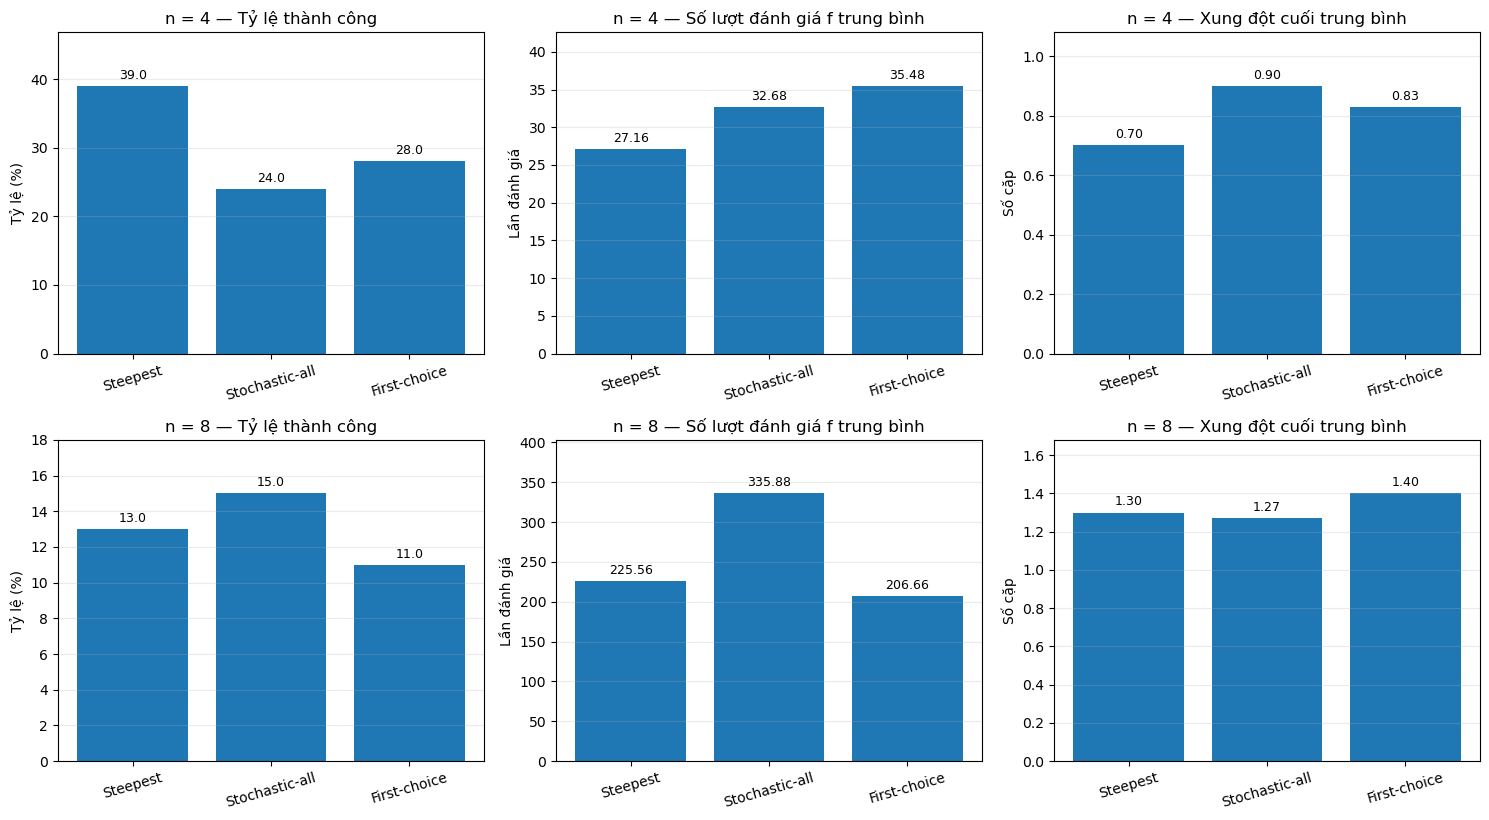

In [20]:
fig, axarr = plt.subplots(2, 3, figsize=(15, 8.3))
for row,n in enumerate(BENCH_N):
    part = benchmark_summary.loc[n].reindex(LABELS)
    labels = ['Steepest', 'Stochastic-all', 'First-choice']
    charts = [
        ('success_rate','Tỷ lệ thành công',100,'Tỷ lệ (%)'),
        ('mean_objective_evals','Số lượt đánh giá f trung bình',1,'Lần đánh giá'),
        ('mean_final_f','Xung đột cuối trung bình',1,'Số cặp'),
    ]
    for col,(key,title,mult,yname) in enumerate(charts):
        ax=axarr[row,col]
        values=(part[key]*mult).to_numpy()
        bars=ax.bar(labels,values)
        ax.set_title(f'n = {n} — {title}')
        ax.set_ylabel(yname)
        ax.tick_params(axis='x',labelrotation=16)
        ax.grid(axis='y',alpha=.25)
        ax.bar_label(bars,fmt='%.1f' if col==0 else '%.2f',padding=3,fontsize=9)
        ax.set_ylim(0,max(1,float(values.max())*1.2))
plt.tight_layout()
plt.show()

### Đường hội tụ đại diện

Chọn **cùng một bàn cờ ban đầu** ở `trial=0` để minh họa, đường $f$ ghi sau mỗi **bước được chấp nhận**. Các đường có độ dài khác nhau do thuật toán dừng sớm. Đây chỉ là hình minh họa một lượt, **không phải** đường hội tụ trung bình; Task 6 trong Bài 8 sẽ khảo sát hội tụ toàn diện hơn.

findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


...

findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


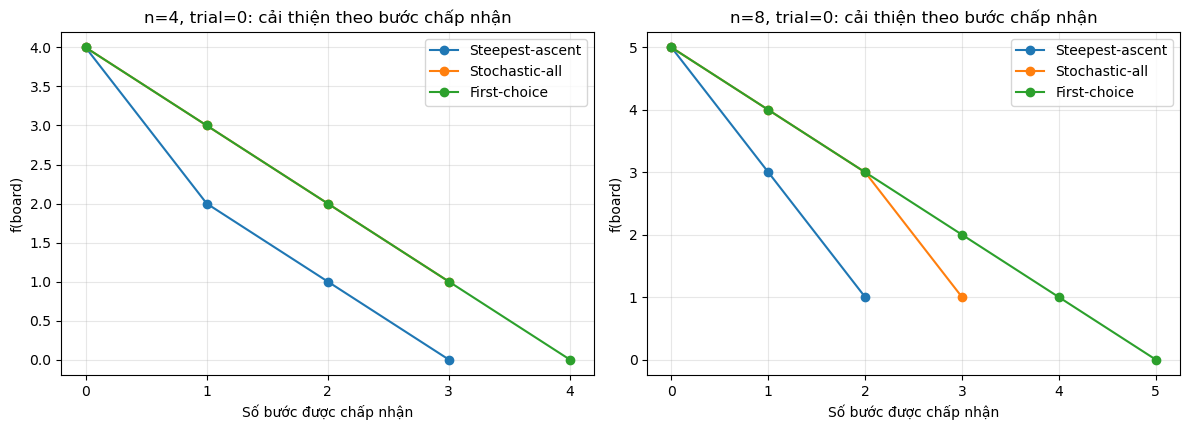

In [21]:
fig, axes=plt.subplots(1,2,figsize=(12,4.4))
for axis,n in zip(axes,BENCH_N):
    for label in LABELS:
        hist=bench_history[n,0,label]
        axis.plot(range(len(hist)),hist,marker='o',label=label)
    axis.set_title(f'n={n}, trial=0: cải thiện theo bước chấp nhận')
    axis.set_xlabel('Số bước được chấp nhận')
    axis.set_ylabel('f(board)')
    axis.set_xticks(range(0,max(len(bench_history[n,0,k]) for k in LABELS)))
    axis.grid(alpha=.3)
    axis.legend()
plt.tight_layout()
plt.show()

## 8. Khảo sát riêng điều kiện dừng First-choice

Với $M=56$ láng giềng ở $n=8$, xét ba ngưỡng $L=M/2=28$, $L=M=56$ và ngưỡng xác suất 95% ($L=167$), sử dụng **100 bàn cờ đầu giống nhau** cho cả ba ngưỡng. Thống kê:
- số lượt đánh giá $f$ trung bình;
- tỷ lệ đạt nghiệm;
- `false_stall_rate`: phần trăm lượt thuật toán dừng do thử quá nhiều lần **nhưng thực tế vẫn còn** láng giềng tốt hơn, kiểm tra độc lập sau khi thuật toán đã kết thúc (**không tính** phần kiểm tra vào thời gian/số đánh giá của thuật toán).

Không áp dụng kiểm định này để tuyên bố bảo đảm 95% cho **toàn bộ lượt chạy**, vì mỗi lần thuật toán có thể đã qua nhiều trạng thái.

In [22]:
n=8
m=n*(n-1)
limits=[m//2, m, first_choice_trial_limit(n)]
assert limits==[28,56,167]
rng=np.random.default_rng(20261016 + 8000)
starts=rng.integers(0,n,size=(100,n))
sens_records=[]
for trial,initial in enumerate(starts):
    for limit in limits:
        tic=perf_counter()
        res=hill_climb_first_choice(initial,seed=90000+8000+trial,
                                    max_no_improvement_trials=limit,**BENCH_BUDGET)
        elapsed=(perf_counter()-tic)*1000
        false_stall=bool(res['stop_reason']=='trial_limit' and has_improving_neighbor(res['board']))
        sens_records.append({'trial':trial,'limit':limit,'success':int(res['success']),
                             'objective_evaluations':res['objective_evaluations'],
                             'runtime_ms':elapsed,'false_stall':int(false_stall)})
sensitivity=pd.DataFrame(sens_records)
sensitivity_summary=(sensitivity.groupby('limit')
    .agg(success_rate=('success','mean'),mean_evaluations=('objective_evaluations','mean'),
         mean_ms=('runtime_ms','mean'),false_stall_rate=('false_stall','mean')))
print('Ngưỡng thử không cải thiện liên tiếp (n=8, cùng 100 bàn cờ):')
display(sensitivity_summary.round(3))

Ngưỡng thử không cải thiện liên tiếp (n=8, cùng 100 bàn cờ):


,success_rate,mean_evaluations,mean_ms,false_stall_rate
limit,,,,
28,0.04,53.21,2.190,0.43
56,0.09,91.54,3.649,0.19
167,0.11,206.66,8.026,0.01


## 9. Nhận xét và kết luận

**So sánh về cơ chế:** Steepest chọn bước tốt nhất toàn bộ láng giềng, còn Stochastic-all chọn ngẫu nhiên một nước tốt. Vì cùng quét hết $M$ láng giềng mỗi vòng, hai biến thể có chi phí đánh giá khoảng $M$ mỗi vòng (trừ việc dừng sớm khi đã đến nghiệm). First-choice chỉ gọi `conflicts()` một lần mỗi lần thử và có thể đi nhanh hơn khi dễ gặp bước tốt; nhưng để tránh ngừng quá sớm ở vùng ít bước tốt, phải cho phép thử nhiều lần. **Không thuật toán nào trong ba thuật toán luôn thoát khỏi cực trị cục bộ**, vì đều chỉ nhận bước giảm $f$.

**Diễn giải từ kết quả thực tế:** Bảng phía trên là căn cứ để nhận xét thuật toán nào đạt tỷ lệ $f=0$ cao hơn và đánh đổi bao nhiêu lượt đánh giá. Chi phí thời gian thực phụ thuộc cách cài đặt, kích thước bài toán và máy đo; không suy ra tốc độ chỉ từ tên thuật toán. Do chạy ngẫu nhiên, 100 lần cho mỗi cấu hình chỉ là ước lượng trên những seed đã chọn, không bảo đảm thứ hạng trên mọi trường hợp.

**Giới hạn:** Không dùng Random Restart, Simulated Annealing, lịch giảm nhiệt hoặc khả năng mở rộng lên $n=12,16,20$ trong Bài 3. Các nội dung đó thuộc Bài 4, 5 và 8. Điều kiện dừng `trial_limit` không phải bằng chứng cực trị cục bộ thực sự.

## 10. Lưu số liệu thô

Hai file CSV bên dưới được tạo từ các bản ghi từng lượt chạy. Dữ liệu này giúp nhóm kiểm tra lại số trung bình, số lượt thành công và truy vết từng seed khi làm Task 6 ở Bài 8. Thời gian thực thi trong file chỉ có ý nghĩa ở môi trường đã đo.

In [23]:
from pathlib import Path
result_dir = Path('ket_qua_bai3')
result_dir.mkdir(parents=True, exist_ok=True)
benchmark_df.to_csv(result_dir / 'bai3_thuc_nghiem_100_luot.csv', index=False)
sensitivity.to_csv(result_dir / 'bai3_first_choice_nguong_dung.csv', index=False)
print('Đã lưu dữ liệu thô:', (result_dir / 'bai3_thuc_nghiem_100_luot.csv'),
      'và', (result_dir / 'bai3_first_choice_nguong_dung.csv'))
assert len(benchmark_df) == 600 and len(sensitivity)==300

Đã lưu dữ liệu thô: ket_qua_bai3\bai3_thuc_nghiem_100_luot.csv và ket_qua_bai3\bai3_first_choice_nguong_dung.csv


## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

### Cài đặt Task 4: Tự viết Random Restart

Mỗi lần gọi lại **một trong ba hàm Hill Climbing của Tri**, không dùng thư viện thuật toán ngoài. Tối đa 100 bàn cờ khởi tạo; lưu best-so-far và toàn bộ chi phí (không tính trùng đánh giá khởi tạo).

In [24]:
def hill_climbing_random_restart(algorithm, n, seed=0, max_starts=100,
                                 total_evaluation_budget=3000, initial_boards=None,
                                 max_steps_per_start=100):
    """Task 4: gọi Hill Climbing nhiều lần, giữ nghiệm tốt nhất.

    Tối đa max_starts bàn cờ (bao gồm lần chạy đầu, tức tối đa 99 lần restart
    nếu max_starts=100). Ngân sách đếm tất cả lời gọi conflicts(), gồm lần
    đo f ban đầu của mỗi lượt. Không lấy kết quả từ implementation khác.
    """
    if not callable(algorithm) or n < 2 or max_starts < 1 or total_evaluation_budget < 1:
        raise ValueError('algorithm hợp lệ, n>=2, số lần/kinh phí phải dương.')
    rng = np.random.default_rng(seed)
    if initial_boards is not None:
        if len(initial_boards) < max_starts:
            raise ValueError('initial_boards phải có ít nhất max_starts bàn cờ.')
        supplied = [check_board(q) for q in initial_boards[:max_starts]]
        if any(len(q)!=n for q in supplied):
            raise ValueError('Không khớp kích thước n của initial_boards.')
    else:
        supplied = None

    best_board, best_f, best_run = None, float('inf'), None
    attempts = []
    consumed = 0
    stop_reason = 'restart_limit'
    for i in range(max_starts):
        remaining = total_evaluation_budget - consumed
        if remaining < 1:
            stop_reason = 'evaluation_budget'
            break
        start = supplied[i].copy() if supplied is not None else rng.integers(0, n, n)
        alg_seed = seed + 1000003 + i
        # Thuật toán một lượt luôn gọi conflicts(start) đúng một lần;
        # các đánh giá sau đó được tính qua max_evaluations.
        if remaining == 1:
            # Không còn đủ chỗ cho một nước đi. Một phép đo f(start) duy nhất.
            f0 = int(conflicts(start))
            result = {'objective_evaluations': 1, 'conflicts': f0,
                      'board': start.copy(), 'iterations': 0,
                      'stop_reason': 'evaluation_budget', 'history': (f0,)}
        else:
            result = algorithm(start, seed=alg_seed, max_steps=max_steps_per_start,
                               max_evaluations=remaining - 1)
        used = int(result['objective_evaluations'])
        if used > remaining:
            raise AssertionError('Thuật toán một lượt vượt ngân sách đánh giá.')
        consumed += used
        if result['conflicts'] < best_f:
            best_f, best_board, best_run = result['conflicts'], result['board'].copy(), i
        attempts.append({
            'start_index': i, 'initial_f': int(result['history'][0]),
            'final_f': result['conflicts'], 'iterations': result['iterations'],
            'objective_evaluations': used, 'stop_reason': result['stop_reason'],
            'best_so_far': int(best_f),
        })
        if best_f == 0:
            stop_reason = 'solved'
            break
        if consumed >= total_evaluation_budget:
            stop_reason = 'evaluation_budget'
            break
    return {
        'algorithm': 'Restart ' + algorithm.__name__,
        'best_board': best_board.copy(), 'best_f': int(best_f),
        'board': best_board.copy(), 'conflicts': int(best_f),
        'success': best_f == 0, 'starts': len(attempts),
        'restarts_used': max(0, len(attempts) - 1),
        'best_start_index': best_run,
        'iterations': sum(r['iterations'] for r in attempts),
        'objective_evaluations': consumed,
        'candidate_evaluations': sum(r['objective_evaluations'] - 1 for r in attempts),
        'stop_reason': stop_reason, 'attempts': attempts,
        'best_history': [r['best_so_far'] for r in attempts],
    }

Steepest         f=0, starts=8, restarts=7, evals=1632, lý do=solved
Stochastic-all   f=0, starts=3, restarts=2, evals=787, lý do=solved


First-choice     f=1, starts=14, restarts=13, evals=3000, lý do=evaluation_budget


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


...

findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


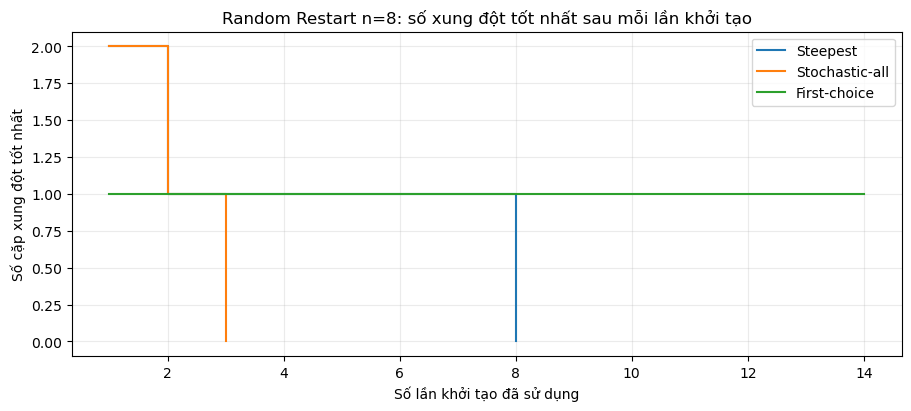

In [25]:
example_starts=np.random.default_rng(71).integers(0,8,size=(100,8))
for name,method in [('Steepest',hill_climb_steepest),('Stochastic-all',hill_climb_stochastic_all),('First-choice',hill_climb_first_choice)]:
    r=hill_climbing_random_restart(method,8,seed=2026,initial_boards=example_starts)
    print(f'{name:16s} f={r["best_f"]}, starts={r["starts"]}, '
          f'restarts={r["restarts_used"]}, evals={r["objective_evaluations"]}, '
          f'lý do={r["stop_reason"]}')
# Đường best-so-far theo lần chạy lại (mỗi điểm tương ứng một khởi tạo mới).
fig,ax=plt.subplots(figsize=(9,4),constrained_layout=True)
for name,method in [('Steepest',hill_climb_steepest),('Stochastic-all',hill_climb_stochastic_all),('First-choice',hill_climb_first_choice)]:
    r=hill_climbing_random_restart(method,8,seed=2026,initial_boards=example_starts)
    ax.step(range(1,r['starts']+1),r['best_history'],where='post',label=name)
ax.set_title('Random Restart n=8: số xung đột tốt nhất sau mỗi lần khởi tạo')
ax.set_xlabel('Số lần khởi tạo đã sử dụng')
ax.set_ylabel('Số cặp xung đột tốt nhất')
ax.yaxis.set_major_locator(MaxNLocator(integer=True)) if 'MaxNLocator' in globals() else None
ax.grid(alpha=.25);ax.legend()
plt.show()

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

### Cài đặt Task 5: Tự viết Simulated Annealing

Cho Δ=f(mới)−f(hiện tại). Nếu Δ≤0 chấp nhận; nếu Δ>0 chấp nhận với p=exp(−Δ/T). `current_history` ghi f thực tế, `best_history` ghi giá trị tốt nhất từng thời điểm. Dùng t bắt đầu từ 1 để lịch logarithmic xác định.

In [26]:
def temperature_exponential(t, T0, alpha):
    """T(t)=T0 * alpha**t, t>=1, 0<alpha<1."""
    return float(T0 * alpha**t)

def temperature_linear(t, T0, eta):
    """T(t)=T0 - eta*t, có thể trở thành không dương."""
    return float(T0 - eta*t)

def temperature_fast(t, T0):
    return float(T0 / (1 + t))

def temperature_logarithmic(t, T0):
    return float(T0 / math.log1p(t))

def simulated_annealing(initial_board, schedule, seed=0, max_steps=2999,
                        total_evaluation_budget=3000):
    """Task 5: SA thuần Python/Numpy do Tri tự cài đặt.

    Không import n_queens_sa.py hay bất kỳ module thuật toán nào của người khác.
    Mỗi bước chọn đều một láng giềng bằng cách dời 1 hậu sang hàng khác
    cùng cột. Δ<=0 nhận chắc chắn; Δ>0 nhận với xác suất exp(-Δ/T).
    Luôn giữ bản sao nghiệm tốt nhất, không chỉ nghiệm hiện tại.
    """
    board = check_board(initial_board)
    if not callable(schedule) or max_steps < 1 or total_evaluation_budget < 1:
        raise ValueError('schedule phải gọi được và ngân sách phải dương.')
    rng = np.random.default_rng(seed)
    current_f = int(conflicts(board))
    initial_f = current_f
    best_board, best_f = board.copy(), current_f
    current_history, best_history = [current_f], [best_f]
    worse_proposed = worse_accepted = plateau_accepted = 0
    steps = 0
    reason = 'step_budget'
    for t in range(1, max_steps + 1):
        if best_f == 0:
            reason = 'solved'
            break
        if steps + 1 >= total_evaluation_budget:
            reason = 'evaluation_budget'
            break
        temperature = float(schedule(t))
        if not math.isfinite(temperature):
            raise ValueError('T(t) không được vô hạn hoặc NaN.')
        if temperature <= 0:
            reason = 'cooled'
            break
        candidate = random_neighbor(board, rng)
        candidate_f = int(conflicts(candidate))
        delta = candidate_f - current_f
        if delta > 0:
            worse_proposed += 1
            # Test log(rng) thay vì tính exp giúp ổn định với T rất nhỏ.
            accepted = math.log(max(float(rng.random()), np.finfo(float).tiny)) < -delta / temperature
            worse_accepted += int(accepted)
        else:
            accepted = True
            plateau_accepted += int(delta == 0)
        if accepted:
            board, current_f = candidate, candidate_f
            if current_f < best_f:
                best_board, best_f = board.copy(), current_f
        steps += 1
        current_history.append(int(current_f))
        best_history.append(int(best_f))
    if best_f == 0:
        reason = 'solved'
    return {
        'algorithm': 'Simulated Annealing',
        'board': best_board.copy(), 'conflicts': int(best_f),
        'best_board': best_board.copy(), 'best_f': int(best_f),
        'current_board': board.copy(), 'final_f': int(current_f),
        'initial_f': int(initial_f), 'success': best_f == 0,
        'steps': steps, 'iterations': steps,
        'candidate_evaluations': steps, 'objective_evaluations': steps + 1,
        'evaluations': steps + 1,
        'stop_reason': reason, 'reason': reason,
        'current_history': current_history,
        'best_history': best_history,
        'history': tuple(best_history),
        'worse_proposed': worse_proposed, 'worse_accepted': worse_accepted,
        'plateau_accepted': plateau_accepted,
    }


Mũ          : f đầu=28 / f tốt nhất=0, các bước=881, nhận bước xấu=95/639
Tuyến tính  : f đầu=28 / f tốt nhất=0, các bước=2809, nhận bước xấu=676/1556
Fast        : f đầu=28 / f tốt nhất=0, các bước=183, nhận bước xấu=1/141


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


...

findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


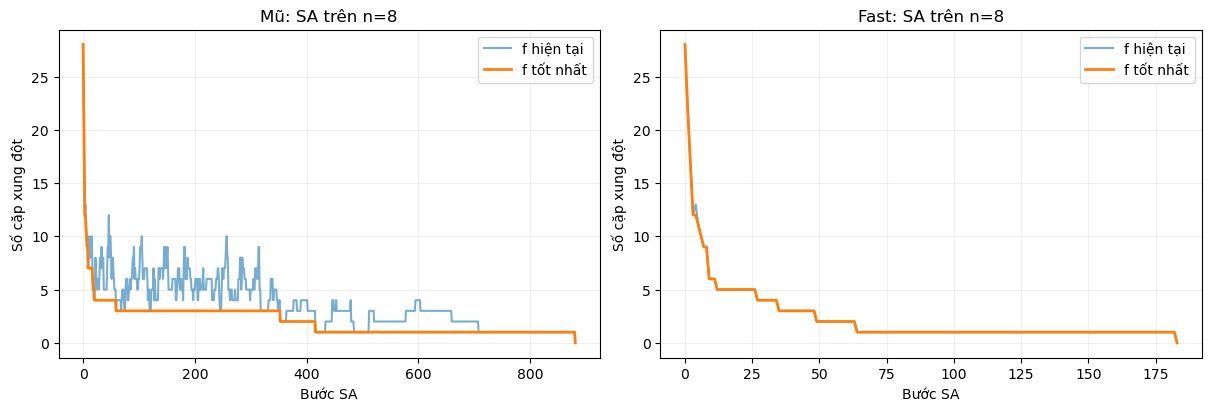

In [27]:
test_board=np.array([0,0,0,0,0,0,0,0])
for schedule_name,schedule in [('Mũ',lambda t:temperature_exponential(t,5,.995)),
                               ('Tuyến tính',lambda t:temperature_linear(t,5,5/3001)),
                               ('Fast',lambda t:temperature_fast(t,5)),
                               ('Logarithmic',lambda t:temperature_logarithmic(t,5))]:
    r=simulated_annealing(test_board,schedule,seed=2026)
    print(f'{schedule_name:12s}: f đầu={r["initial_f"]} / f tốt nhất={r["best_f"]}, '
          f'các bước={r["steps"]}, nhận bước xấu={r["worse_accepted"]}/{r["worse_proposed"]}')
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for i,(name,schedule) in enumerate([('Mũ',lambda t:temperature_exponential(t,5,.995)),
                                   ('Fast',lambda t:temperature_fast(t,5))]):
    r=simulated_annealing(test_board,schedule,seed=2026)
    axes[i].plot(r['current_history'],label='f hiện tại',alpha=.6)
    axes[i].plot(r['best_history'],label='f tốt nhất',linewidth=2)
    axes[i].set_title(f'{name}: SA trên n=8')
    axes[i].set_xlabel('Bước SA');axes[i].set_ylabel('Số cặp xung đột')
    axes[i].grid(alpha=.2);axes[i].legend()
plt.show()

### Kiểm chứng các thuật toán Bài 4 và thực nghiệm n=4,8

So sánh 3 kiểu Random Restart và SA trên 40 seed, giới hạn **3.000 lần gọi conflicts()** cho toàn bộ lần chạy. Khảo sát thêm `T0`, alpha và hai lịch Linear/Fast trên 30 seed cho mỗi kích thước. Kết quả được tính lại ngay trong notebook, không dùng số liệu từ bên ngoài.

In [28]:
# Oracle độc lập: đếm chính xác mọi cặp hậu, không dùng cách đếm theo nhóm.
def conflicts_oracle(board):
    return sum(bool(board[i] == board[j] or abs(int(board[i])-int(board[j])) == j-i)
               for i in range(len(board)) for j in range(i+1, len(board)))

from itertools import product
for values in product(range(4), repeat=4):
    assert int(conflicts(values)) == conflicts_oracle(values)
assert int(conflicts([1, 3, 0, 2])) == 0
rng_test = np.random.default_rng(91025)
for n in (4, 8):
    for _ in range(40):
        board = rng_test.integers(0, n, n)
        original = board.copy()
        for fn in (hill_climb_steepest, hill_climb_stochastic_all, hill_climb_first_choice):
            outcome = fn(board, seed=19)
            assert outcome['conflicts'] == conflicts_oracle(outcome['board'])
            assert np.array_equal(board, original)
        fixed_starts = [rng_test.integers(0, n, n) for j in range(100)]
        for fn in (hill_climb_steepest, hill_climb_stochastic_all, hill_climb_first_choice):
            run = hill_climbing_random_restart(fn, n, seed=33, max_starts=100,
                    total_evaluation_budget=500, initial_boards=fixed_starts)
            assert run['best_f'] == conflicts_oracle(run['best_board'])
            assert run['starts'] <= 100 and run['objective_evaluations'] <= 500
            assert run['restarts_used'] == run['starts'] - 1
            assert run['best_f'] == min(x['final_f'] for x in run['attempts'])
            assert all(x['best_so_far'] >= y['best_so_far'] for x,y in zip(run['attempts'],run['attempts'][1:]))
        schedule_test = lambda t: temperature_exponential(t, 5.0, 0.995)
        r1 = simulated_annealing(board, schedule_test, seed=19, max_steps=400, total_evaluation_budget=401)
        r2 = simulated_annealing(board, schedule_test, seed=19, max_steps=400, total_evaluation_budget=401)
        assert np.array_equal(r1['best_board'], r2['best_board'])
        assert r1['current_history'] == r2['current_history']
        assert np.array_equal(board, original)
        assert r1['best_f'] == conflicts_oracle(r1['best_board'])
        assert r1['final_f'] == conflicts_oracle(r1['current_board'])
        assert r1['best_f'] == min(r1['current_history'])
        assert len(r1['best_history']) == len(r1['current_history']) == r1['steps']+1
        assert all(a >= b for a,b in zip(r1['best_history'],r1['best_history'][1:]))
        assert r1['objective_evaluations'] <= 401
        assert 0 <= r1['worse_accepted'] <= r1['worse_proposed']
assert simulated_annealing([1,3,0,2],lambda t:2.0)['steps'] == 0
assert hill_climbing_random_restart(hill_climb_steepest,4,
    initial_boards=[np.array([1,3,0,2])]*100)['starts'] == 1
assert hill_climbing_random_restart(hill_climb_steepest,4, total_evaluation_budget=1)['objective_evaluations'] == 1
for invalid in ([4,0,0,0], [-1,0,0,0]):
    try:
        check_board(invalid)
        raise AssertionError('check_board phải từ chối board không hợp lệ')
    except ValueError:
        pass
print('PASS — oracle, n=4 exhaustive, kiểm thử n=4/8, restart, SA, seed, ngân sách và tính không sửa input')

PASS — oracle, n=4 exhaustive, kiểm thử n=4/8, restart, SA, seed, ngân sách và tính không sửa input


In [29]:
import pandas as pd
from IPython.display import display

BENCH_TRIALS = 40
MAX_STARTS = 100
FAIR_EVAL_BUDGET = 3000
MAX_SA_STEPS = FAIR_EVAL_BUDGET - 1
restart_methods = {
    'Restart Steepest': hill_climb_steepest,
    'Restart Stochastic-all': hill_climb_stochastic_all,
    'Restart First-choice': hill_climb_first_choice,
}
sa_schedule = lambda t: temperature_exponential(t, T0=5.0, alpha=0.995)
main_records = []
main_examples = {}
main_raw = {}
from time import perf_counter
for n in (4, 8):
    for trial in range(BENCH_TRIALS):
        # Đồng bộ bộ khởi tạo giữa 3 biến thể Restart; SA nhận cùng board đầu.
        seed = 20261016 + 1000*n + trial
        starts = np.random.default_rng(seed).integers(0, n, size=(MAX_STARTS, n))
        algorithm_seed = 90000 + 1000*n + trial
        jobs = list(restart_methods.items()) + [('SA - Exponential', None)]
        jobs = jobs[trial % len(jobs):] + jobs[:trial % len(jobs)]
        for name, fn in jobs:
            timer = perf_counter()
            if fn is None:
                out = simulated_annealing(starts[0], sa_schedule, seed=algorithm_seed,
                    max_steps=MAX_SA_STEPS, total_evaluation_budget=FAIR_EVAL_BUDGET)
                starts_count = 1
            else:
                out = hill_climbing_random_restart(fn, n, seed=algorithm_seed,
                    max_starts=MAX_STARTS, total_evaluation_budget=FAIR_EVAL_BUDGET,
                    initial_boards=starts)
                starts_count = out['starts']
            elapsed_ms = (perf_counter() - timer) * 1000
            assert out['objective_evaluations'] <= FAIR_EVAL_BUDGET
            assert out['conflicts'] == conflicts_oracle(out['board'])
            main_records.append({
                'n': n, 'trial': trial, 'algorithm': name, 'initial_f': int(conflicts(starts[0])),
                'best_f': out['conflicts'], 'success': int(out['success']),
                'starts': starts_count, 'iterations': out['iterations'],
                'objective_evaluations': out['objective_evaluations'],
                'runtime_ms': elapsed_ms, 'stop_reason': out['stop_reason'],
            })
            main_raw[(n,trial,name)] = out
main_df = pd.DataFrame(main_records)
main_summary = (main_df.groupby(['n','algorithm'], sort=False)
    .agg(trials=('success','size'), success_rate=('success','mean'),
         mean_best_f=('best_f','mean'), median_best_f=('best_f','median'),
         mean_starts=('starts','mean'), mean_iterations=('iterations','mean'),
         mean_evaluations=('objective_evaluations','mean'),
         median_evaluations=('objective_evaluations','median'),
         mean_runtime_ms=('runtime_ms','mean'), median_runtime_ms=('runtime_ms','median')))
print('BẢNG 1 — Mỗi cấu hình có 40 lượt độc lập; tối đa 100 khởi tạo / 3.000 evaluations')
display(main_summary.round(3))
print('LÝ DO DỪNG (không đánh đồng hết ngân sách với local optimum)')
display(pd.crosstab([main_df.n,main_df.algorithm], main_df.stop_reason))
assert len(main_df) == 2*4*BENCH_TRIALS

BẢNG 1 — Mỗi cấu hình có 40 lượt độc lập; tối đa 100 khởi tạo / 3.000 evaluations


trials  success_rate  mean_best_f  median_best_f  \
n algorithm                                                                  
4 Restart Steepest            40         1.000        0.000            0.0   
  Restart Stochastic-all      40         1.000        0.000            0.0   
  Restart First-choice        40         1.000        0.000            0.0   
  SA - Exponential            40         1.000        0.000            0.0   
8 Restart Steepest            40         0.875        0.125            0.0   
  Restart Stochastic-all      40         0.700        0.300            0.0   
  Restart First-choice        40         0.750        0.250            0.0   
  SA - Exponential            40         0.975        0.025            0.0   

                          mean_starts  mean_iterations  mean_evaluations  \
n algorithm                                                                
4 Restart Steepest              2.500            3.925            67.600   
  Restart Stochastic-all        3.550            6.500           112.150   
  Restart First-choice          3.175            5.975           113.575   
  SA - Exponential              1.000           92.775            93.775   
8 Restart Steepest              7.575           16.750          1184.975   
  Restart Stochastic-all       12.250           25.875          1714.650   
  Restart First-choice          8.525           40.950          1725.775   
  SA - Exponential              1.000          943.875           944.875   

                          median_evaluations  mean_runtime_ms  \
n algorithm                                                     
4 Restart Steepest                      50.0            4.416   
  Restart Stochastic-all               105.0            5.566   
  Restart First-choice                 100.5            7.492   
  SA - Exponential                      64.0            4.714   
8 Restart Steepest                     956.5           31.702   
  Restart Stochastic-all              1432.5           46.416   
  Restart First-choice                1748.0           78.331   
  SA - Exponential                     712.5           57.844   

                          median_runtime_ms  
n algorithm                                  
4 Restart Steepest                    4.170  
  Restart Stochastic-all              5.216  
  Restart First-choice                5.733  
  SA - Exponential                    3.165  
8 Restart Steepest                   23.280  
  Restart Stochastic-all             41.216  
  Restart First-choice               78.016  
  SA - Exponential                   44.743

LÝ DO DỪNG (không đánh đồng hết ngân sách với local optimum)


stop_reason               evaluation_budget  solved  step_budget
n algorithm                                                     
4 Restart First-choice                    0      40            0
  Restart Steepest                        0      40            0
  Restart Stochastic-all                  0      40            0
  SA - Exponential                        0      40            0
8 Restart First-choice                   10      30            0
  Restart Steepest                        5      35            0
  Restart Stochastic-all                 12      28            0
  SA - Exponential                        0      39            1

findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


...

findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


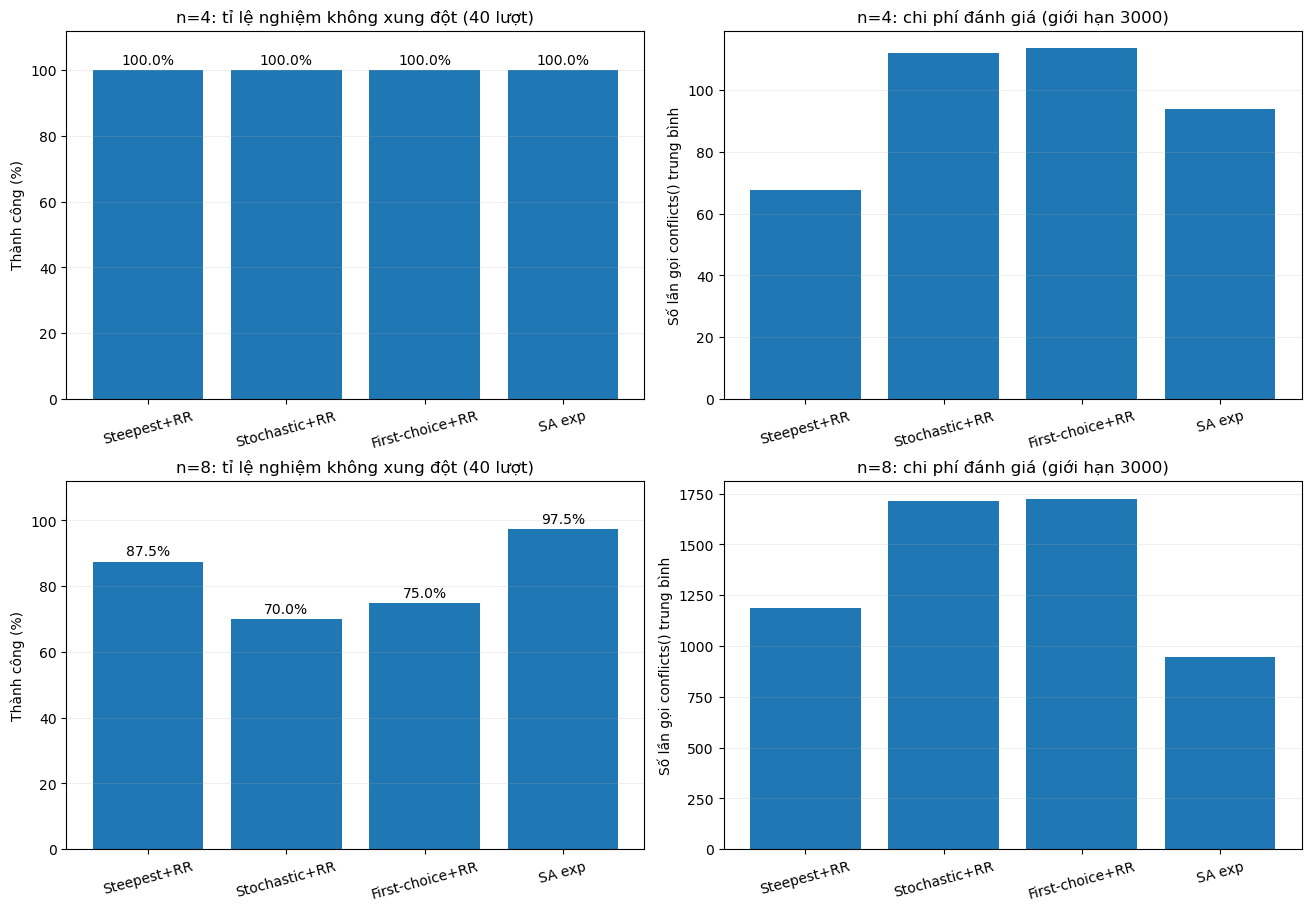

In [30]:
from matplotlib.ticker import MaxNLocator
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for i,n in enumerate((4,8)):
    summary=main_summary.loc[n]
    labels=summary.index.to_list()
    success=100*summary['success_rate'].to_numpy()
    a=axes[i,0]
    bars=a.bar(range(len(labels)),success)
    a.bar_label(bars,labels=[f'{x:.1f}%' for x in success],padding=2)
    a.set_xticks(range(len(labels)),['Steepest+RR','Stochastic+RR','First-choice+RR','SA exp'],rotation=15)
    a.set_ylim(0,112)
    a.set_ylabel('Thành công (%)')
    a.set_title(f'n={n}: tỉ lệ nghiệm không xung đột ({BENCH_TRIALS} lượt)')
    a.grid(axis='y',alpha=.2)
    a=axes[i,1]
    a.bar(range(len(labels)),summary['mean_evaluations'])
    a.set_xticks(range(len(labels)),['Steepest+RR','Stochastic+RR','First-choice+RR','SA exp'],rotation=15)
    a.set_ylabel('Số lần gọi conflicts() trung bình')
    a.set_title(f'n={n}: chi phí đánh giá (giới hạn {FAIR_EVAL_BUDGET})')
    a.grid(axis='y',alpha=.2)
plt.show()

### Thí nghiệm độ nhạy của Simulated Annealing

Thử 2×2 cấu hình (T0,alpha), thêm lịch tuyến tính và Fast. Số liệu chỉ có ý nghĩa với seed, ngân sách và cấu hình đã chọn.

In [31]:
# Thiết kế thí nghiệm nhân tố 2x2 (T0 x alpha) + hai lịch nhiệt khác.
# Bài 4 tự triển khai SA, không phụ thuộc notebook Bài 5 của nhóm.
SA_TRIALS = 30
schedules = {
    'Exp T0=2 α=.98': lambda t: temperature_exponential(t,2.0,.98),
    'Exp T0=2 α=.995': lambda t: temperature_exponential(t,2.0,.995),
    'Exp T0=8 α=.98': lambda t: temperature_exponential(t,8.0,.98),
    'Exp T0=8 α=.995': lambda t: temperature_exponential(t,8.0,.995),
    'Linear T0=5': lambda t: temperature_linear(t,5.0,5.0/(MAX_SA_STEPS+2)),
    'Fast T0=5': lambda t: temperature_fast(t,5.0),
}
sa_records=[]
sa_histories={}
for n in (4,8):
    for trial in range(SA_TRIALS):
        board_seed=177000+1000*n+trial
        algo_seed=288000+1000*n+trial
        start=np.random.default_rng(board_seed).integers(0,n,size=n)
        names=list(schedules)
        names=names[trial%len(names):]+names[:trial%len(names)]
        for name in names:
            tic=perf_counter()
            r=simulated_annealing(start, schedules[name], seed=algo_seed,
                max_steps=MAX_SA_STEPS,total_evaluation_budget=FAIR_EVAL_BUDGET)
            elapsed_ms=(perf_counter()-tic)*1000
            assert r['best_f'] == conflicts_oracle(r['best_board'])
            sa_records.append({
                'n':n,'trial':trial,'schedule':name,'initial_f':int(conflicts(start)),
                'best_f':r['best_f'],'final_f':r['final_f'], 'success':int(r['success']),
                'steps':r['steps'],'objective_evaluations':r['objective_evaluations'],
                'worse_proposed':r['worse_proposed'],'worse_accepted':r['worse_accepted'],
                'runtime_ms':elapsed_ms,'stop_reason':r['stop_reason'],
            })
            sa_histories[(n,trial,name)]=r['best_history']
sa_df=pd.DataFrame(sa_records)
sa_summary=(sa_df.groupby(['n','schedule'],sort=False)
    .agg(trials=('success','size'),success_rate=('success','mean'),
         mean_best_f=('best_f','mean'),mean_steps=('steps','mean'),
         mean_evaluations=('objective_evaluations','mean'),
         worse_proposed=('worse_proposed','sum'),worse_accepted=('worse_accepted','sum'),
         median_ms=('runtime_ms','median')))
sa_summary['worse_accept_rate']=sa_summary.worse_accepted / sa_summary.worse_proposed.replace({0:np.nan})
print('BẢNG 2 — 30 lượt cho mỗi lịch và từng n; cùng board/seed giữa các lịch')
display(sa_summary.round(3))
assert len(sa_df) == 2*SA_TRIALS*len(schedules)

BẢNG 2 — 30 lượt cho mỗi lịch và từng n; cùng board/seed giữa các lịch


trials  success_rate  mean_best_f  mean_steps  \
n schedule                                                         
4 Exp T0=2 α=.98       30         1.000        0.000      54.767   
  Exp T0=2 α=.995      30         1.000        0.000      77.000   
  Exp T0=8 α=.98       30         1.000        0.000      79.500   
  Exp T0=8 α=.995      30         1.000        0.000      88.767   
  Linear T0=5          30         1.000        0.000     105.100   
  Fast T0=5            30         1.000        0.000      43.200   
8 Exp T0=2 α=.98       30         0.900        0.100    1007.767   
  Exp T0=2 α=.995      30         1.000        0.000     758.767   
  Exp T0=8 α=.98       30         1.000        0.000     616.300   
  Exp T0=8 α=.995      30         0.967        0.033    1121.000   
  Linear T0=5          30         0.433        0.600    2693.467   
  Fast T0=5            30         0.933        0.067     836.800   

                   mean_evaluations  worse_proposed  worse_accepted  \
n schedule                                                            
4 Exp T0=2 α=.98             55.767             987             182   
  Exp T0=2 α=.995            78.000            1238             381   
  Exp T0=8 α=.98             80.500            1193             509   
  Exp T0=8 α=.995            89.767            1068             776   
  Linear T0=5               106.100            1267             931   
  Fast T0=5                  44.200             936              26   
8 Exp T0=2 α=.98           1008.767           27717             256   
  Exp T0=2 α=.995           759.767           18576            1156   
  Exp T0=8 α=.98            617.300           15474             874   
  Exp T0=8 α=.995          1122.000           25057            3633   
  Linear T0=5              2694.467           44643           18753   
  Fast T0=5                 837.800           23238              26   

                   median_ms  worse_accept_rate  
n schedule                                       
4 Exp T0=2 α=.98       1.838              0.184  
  Exp T0=2 α=.995      2.870              0.308  
  Exp T0=8 α=.98       3.661              0.427  
  Exp T0=8 α=.995      2.716              0.727  
  Linear T0=5          2.627              0.735  
  Fast T0=5            1.490              0.028  
8 Exp T0=2 α=.98      36.020              0.009  
  Exp T0=2 α=.995     41.418              0.062  
  Exp T0=8 α=.98      28.811              0.056  
  Exp T0=8 α=.995     54.518              0.145  
  Linear T0=5        168.854              0.420  
  Fast T0=5           37.468              0.001

findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


...

findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


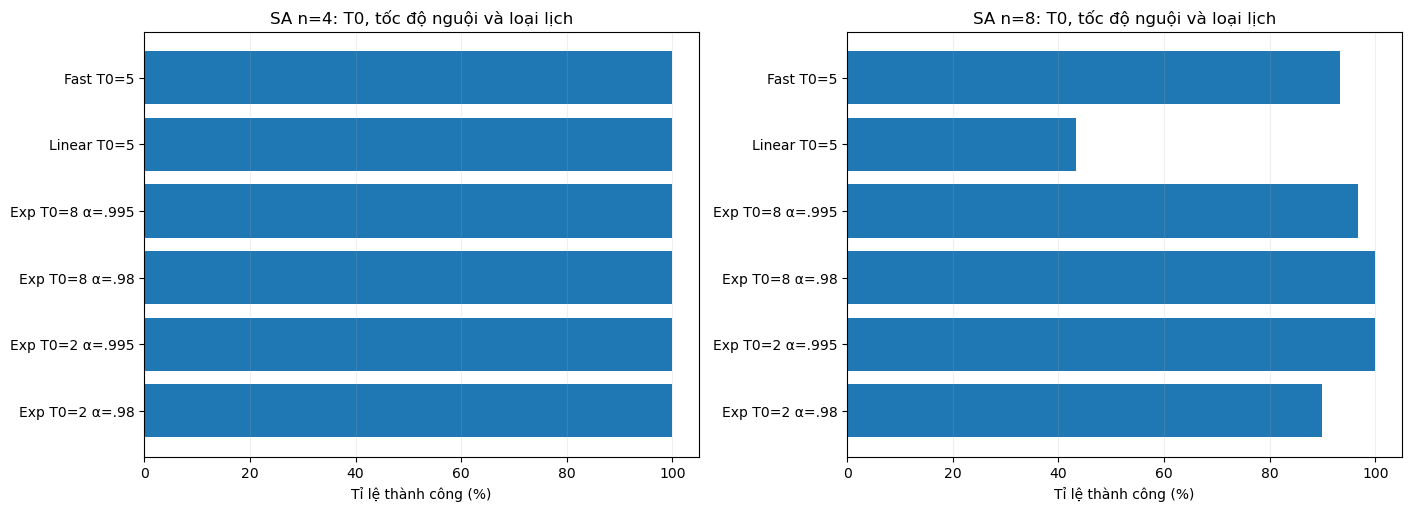

findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


...

findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


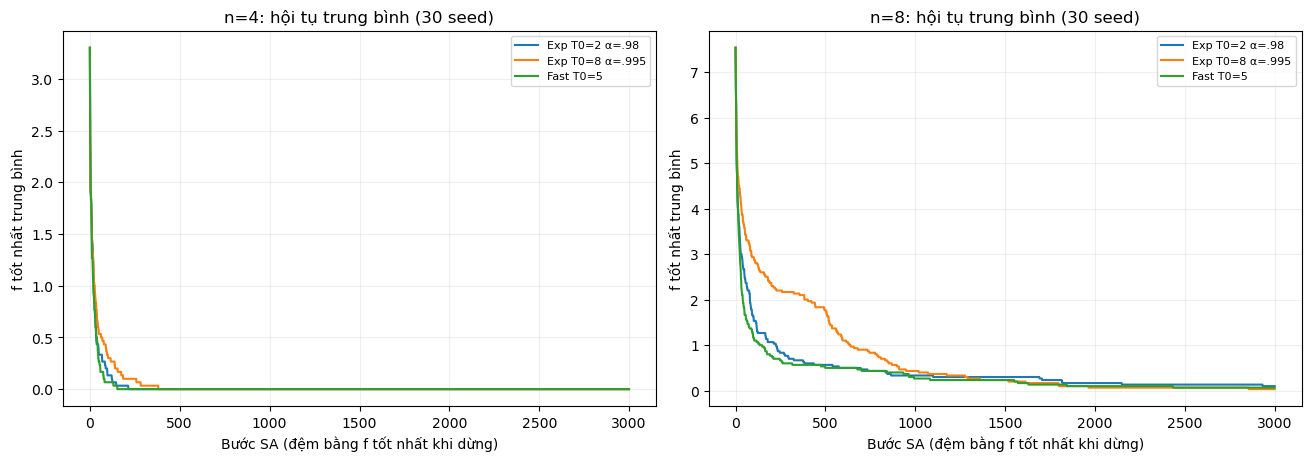

In [32]:
fig, axes=plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
for ax,n in zip(axes,(4,8)):
    table=sa_summary.loc[n]
    labels=table.index.tolist()
    ax.barh(range(len(labels)),100*table.success_rate)
    ax.set_yticks(range(len(labels)),labels)
    ax.set_xlim(0,105)
    ax.set_xlabel('Tỉ lệ thành công (%)')
    ax.set_title(f'SA n={n}: T0, tốc độ nguội và loại lịch')
    ax.grid(axis='x',alpha=.2)
plt.show()
# Các chuỗi là f tốt nhất, không phải chỉ số trạng thái hiện tại.
fig,axes=plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
for ax,n in zip(axes,(4,8)):
    for name in ('Exp T0=2 α=.98','Exp T0=8 α=.995','Fast T0=5'):
        histories=[sa_histories[n,trial,name] for trial in range(SA_TRIALS)]
        arr=np.stack([np.pad(h,(0,FAIR_EVAL_BUDGET-len(h)),mode='edge') for h in histories])
        ax.plot(np.mean(arr,axis=0),label=name)
    ax.set_title(f'n={n}: hội tụ trung bình ({SA_TRIALS} seed)')
    ax.set_xlabel('Bước SA (đệm bằng f tốt nhất khi dừng)')
    ax.set_ylabel('f tốt nhất trung bình')
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
plt.show()

### Nhận xét Bài 4 dựa trực tiếp trên bảng và đồ thị

In [33]:
from IPython.display import Markdown
paragraphs=[]
for n in (4,8):
    part=main_summary.loc[n]
    ranks=part.sort_values('success_rate',ascending=False)
    best_rate=float(ranks.success_rate.iloc[0])
    leaders=ranks.index[ranks.success_rate==best_rate].tolist()
    paragraphs.append(
        f'- **n={n}** — tỷ lệ thành công cao nhất ở bảng chính: '
        f'**{100*best_rate:.1f}%**, đạt bởi **{", ".join(leaders)}** '
        f'({BENCH_TRIALS} lần). Số phép đánh giá trung bình thấp nhất: '
        f'**{part.mean_evaluations.idxmin()}** ({part.mean_evaluations.min():.1f} lần). '
        'Hai tiêu chí là khác nhau; không suy ra phương pháp tối ưu tuyệt đối.'
    )
    table=sa_summary.loc[n]
    top=table.success_rate.max()
    leaders2=table.index[table.success_rate==top].tolist()
    paragraphs.append(f'  - Khảo sát lịch nhiệt n={n}: tỷ lệ cao nhất **{100*top:.1f}%** '
                      f'ở **{", ".join(leaders2)}**. '
                      'Các chênh lệch nhỏ cần được kiểm tra với nhiều seed hơn.')
paragraphs.append('- **Giới hạn:** Đây là thống kê trên 40 hoặc 30 seed/cấu hình, với trần '
    f'{FAIR_EVAL_BUDGET} đánh giá và chỉ n=4,8; chưa suy ra một phương pháp tốt nhất cho mọi n. '
    'Thời gian phụ thuộc môi trường; thời gian tạo dữ liệu và vẽ hình không nằm trong phép đo thuật toán.')
display(Markdown('\n'.join(paragraphs)))

- **n=4** — tỷ lệ thành công cao nhất ở bảng chính: **100.0%**, đạt bởi **Restart Steepest, Restart Stochastic-all, Restart First-choice, SA - Exponential** (40 lần). Số phép đánh giá trung bình thấp nhất: **Restart Steepest** (67.6 lần). Hai tiêu chí là khác nhau; không suy ra phương pháp tối ưu tuyệt đối.
  - Khảo sát lịch nhiệt n=4: tỷ lệ cao nhất **100.0%** ở **Exp T0=2 α=.98, Exp T0=2 α=.995, Exp T0=8 α=.98, Exp T0=8 α=.995, Linear T0=5, Fast T0=5**. Các chênh lệch nhỏ cần được kiểm tra với nhiều seed hơn.
- **n=8** — tỷ lệ thành công cao nhất ở bảng chính: **97.5%**, đạt bởi **SA - Exponential** (40 lần). Số phép đánh giá trung bình thấp nhất: **SA - Exponential** (944.9 lần). Hai tiêu chí là khác nhau; không suy ra phương pháp tối ưu tuyệt đối.
  - Khảo sát lịch nhiệt n=8: tỷ lệ cao nhất **100.0%** ở **Exp T0=2 α=.995, Exp T0=8 α=.98**. Các chênh lệch nhỏ cần được kiểm tra với nhiều seed hơn.
- **Giới hạn:** Đây là thống kê trên 40 hoặc 30 seed/cấu hình, với trần 3000 đánh giá và chỉ n=4,8; chưa suy ra một phương pháp tốt nhất cho mọi n. Thời gian phụ thuộc môi trường; thời gian tạo dữ liệu và vẽ hình không nằm trong phép đo thuật toán.

In [34]:
from pathlib import Path
output_dir=Path('ket_qua_bai4')
output_dir.mkdir(exist_ok=True)
main_df.to_csv(output_dir/'bai4_so_sanh_restart_sa.csv',index=False,encoding='utf-8-sig')
sa_df.to_csv(output_dir/'bai4_khao_sat_lich_nhiet.csv',index=False,encoding='utf-8-sig')
main_summary.to_csv(output_dir/'bai4_tong_hop.csv',encoding='utf-8-sig')
sa_summary.to_csv(output_dir/'bai4_tong_hop_lich_nhiet.csv',encoding='utf-8-sig')
print('Đã lưu dữ liệu thực nghiệm trong:',output_dir.resolve())

Đã lưu dữ liệu thực nghiệm trong: D:\SGU\CNTT\TTNTNC\sgu-team-2026-advanced-ai-subject\weekly assignments\lab03 - local search\ket_qua_bai4


## Task 6: Algorithm Behavior Analysis [20 Points]

### Bài 8 — Quy trình so sánh và phân tích hành vi thuật toán

> **Lưu ý tích hợp và tính nhất quán phương pháp:**
> Toàn bộ các thực nghiệm so sánh trong Task 6 được thực thi **trực tiếp bằng các thuật toán do Tri cài đặt trong Task 1–5** (`hill_climb_steepest`, `hill_climb_stochastic_all`, `hill_climb_first_choice`, `simulated_annealing`), thông qua adapter chuẩn hóa giao diện.
>
> **Thiết kế thực nghiệm:**
> - Chạy **100 lần** độc lập cho mỗi $n = 4$ và $n = 8$.
> - Các thuật toán trong cùng một lần thử (trial) nhận **cùng bàn cờ ban đầu** được sinh từ seed `80000 + 1000*n + trial`.
> - Seed nội bộ của thuật toán là `90000 + 1000*n + trial`.
> - Mỗi lần chạy có ngân sách tối đa **5.000 đánh giá hàm mục tiêu** (bao gồm đánh giá bàn cờ ban đầu).
> - SA sử dụng hàm `simulated_annealing` của Tri với lịch mũ $T(t) = 5.0 \times 0.995^t$, tối đa 4.999 bước lặp.
> - Thuật toán dừng sớm khi tìm được lời giải ($f = 0$) hoặc chạm giới hạn ngân sách / cực tiểu địa phương.

In [35]:
# Adapter kết nối trực tiếp các thuật toán Task 1–5 của Tri với Task 6
import pandas as pd
from time import perf_counter
from IPython.display import display, Markdown

def queens_steepest(board, max_evals=5000, seed=0):
    if max_evals <= 1:
        f0 = int(conflicts(board))
        return result_dict('Steepest-ascent', board, f0, [f0], 0, 'evaluation_budget')
    return hill_climb_steepest(board, seed=seed, max_steps=max_evals, max_evaluations=max_evals - 1)

def queens_stochastic(board, max_evals=5000, seed=0):
    if max_evals <= 1:
        f0 = int(conflicts(board))
        return result_dict('Stochastic-all', board, f0, [f0], 0, 'evaluation_budget')
    return hill_climb_stochastic_all(board, seed=seed, max_steps=max_evals, max_evaluations=max_evals - 1)

def queens_first_choice(board, max_evals=5000, seed=0, operator='any'):
    if max_evals <= 1:
        f0 = int(conflicts(board))
        return result_dict('First-choice', board, f0, [f0], 0, 'evaluation_budget')
    return hill_climb_first_choice(board, seed=seed, max_steps=max_evals, max_evaluations=max_evals - 1,
                                  operator=operator)

def queens_sa_for_comparison(board, max_evals=5000, seed=0):
    return simulated_annealing(board, schedule=lambda t: temperature_exponential(t, 5.0, 0.995),
                               seed=seed, max_steps=max(1, max_evals - 1), total_evaluation_budget=max_evals)

queens_algorithms = {
    'Steepest HC': queens_steepest,
    'Stochastic HC': queens_stochastic,
    'First-choice HC': queens_first_choice,
    'SA': queens_sa_for_comparison,
}

queen_records = []
queen_runs = {}

def measure_queens(n, trial, names):
    seed = 80000 + 1000 * n + trial
    board = np.random.default_rng(seed).integers(0, n, size=n)
    untouched = board.copy()
    shift = trial % len(names)
    for name in names[shift:] + names[:shift]:
        started = perf_counter()
        run = queens_algorithms[name](board, max_evals=5000, seed=seed + 10000)
        milliseconds = (perf_counter() - started) * 1000
        assert run['best_f'] == conflicts(run['best_board'])
        assert np.array_equal(board, untouched)
        assert run['evaluations'] <= 5000
        assert np.all(np.diff(run['best_history']) <= 0)
        queen_runs[n, trial, name] = run
        queen_records.append({'n': n, 'Thuật toán': name, 'f': run['best_f'],
                              'ms': milliseconds, 'Đánh giá': run['evaluations']})

print('Đang chạy thực nghiệm 100 lần cho n = 4 và n = 8...')
for n in [4, 8]:
    for trial in range(100):
        measure_queens(n, trial, list(queens_algorithms))

queen_results = pd.DataFrame(queen_records)
queen_comparison = queen_results.groupby(['n', 'Thuật toán'], sort=False).agg(
    so_lan=('f', 'size'),
    thoi_gian_ms_TB=('ms', 'mean'),
    f_TB=('f', 'mean'),
    thanh_cong_phan_tram=('f', lambda values: 100 * (values == 0).mean()),
    danh_gia_TB=('Đánh giá', 'mean'),
)
display(queen_comparison.round(3))


Đang chạy thực nghiệm 100 lần cho n = 4 và n = 8...


so_lan  thoi_gian_ms_TB  f_TB  thanh_cong_phan_tram  \
n Thuật toán                                                             
4 Steepest HC         100            0.565  0.62                  45.0   
  Stochastic HC       100            0.838  0.83                  29.0   
  First-choice HC     100            1.450  0.86                  27.0   
  SA                  100            4.957  0.00                 100.0   
8 Steepest HC         100            5.338  1.29                   8.0   
  Stochastic HC       100            7.558  1.35                  13.0   
  First-choice HC     100            8.944  1.36                  13.0   
  SA                  100           55.135  0.01                  99.0   

                   danh_gia_TB  
n Thuật toán                    
4 Steepest HC            28.00  
  Stochastic HC          34.60  
  First-choice HC        37.52  
  SA                    107.96  
8 Steepest HC           232.28  
  Stochastic HC         309.56  
  First-choice HC       206.13  
  SA                    973.43

### Algorithm Convergence

Phân tích hành vi hội tụ điển hình của từng thuật toán trên bài toán 8-Queens:
- **Steepest-ascent HC:** Giảm xung đột rất nhanh ở những bước đầu tiên do luôn chọn hướng dốc nhất, nhưng nhanh chóng bị kẹt ở cực tiểu địa phương hoặc cao nguyên (plateau) khi không còn láng giềng nào tốt hơn.
- **Stochastic HC:** Tốc độ giảm xung đột ban đầu vừa phải hơn so với Steepest vì chọn ngẫu nhiên trong tập các bước đi cải thiện, có khả năng đi vào các nhánh tìm kiếm đa dạng hơn nhưng vẫn dừng khi không còn láng giềng cải thiện.
- **First-choice HC:** Điểm hội tụ có các đoạn nằm ngang (plateaus) do lấy mẫu ngẫu nhiên các láng giềng không cải thiện; dừng khi vượt ngưỡng kiên nhẫn xác suất (trial limit).
- **Simulated Annealing (SA):** Đường $f$ hiện tại (`current_history`) dao động liên tục nhờ cơ chế chấp nhận bước xấu có xác suất giảm dần theo nhiệt độ, giúp thuật toán thoát khỏi các bẫy cực tiểu địa phương. Đường $f$ tốt nhất (`best_history`) luôn đơn điệu giảm và đạt tỷ lệ giải thành công vượt trội.

findfont: Font family 'Noto Sans Display' not found.


findfont: Font family ['Noto Sans Display'] not found. Falling back to DejaVu Sans.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


...

findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


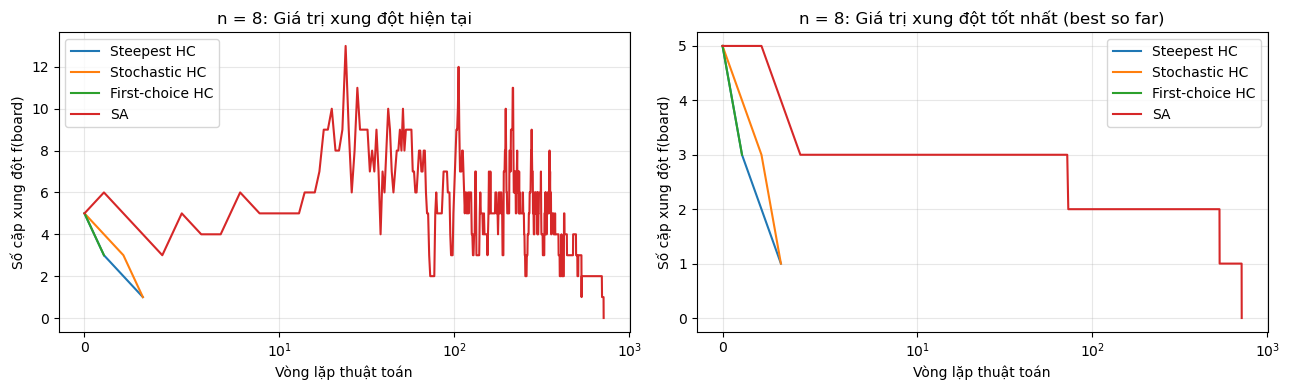

- n = 4, **Steepest HC**: f trung bình 0.62, giải được 45%, thời gian 0.56 ms, đánh giá TB 28.0.
- n = 4, **Stochastic HC**: f trung bình 0.83, giải được 29%, thời gian 0.84 ms, đánh giá TB 34.6.
- n = 4, **First-choice HC**: f trung bình 0.86, giải được 27%, thời gian 1.45 ms, đánh giá TB 37.5.
- n = 4, **SA**: f trung bình 0.00, giải được 100%, thời gian 4.96 ms, đánh giá TB 108.0.
- n = 8, **Steepest HC**: f trung bình 1.29, giải được 8%, thời gian 5.34 ms, đánh giá TB 232.3.
- n = 8, **Stochastic HC**: f trung bình 1.35, giải được 13%, thời gian 7.56 ms, đánh giá TB 309.6.
- n = 8, **First-choice HC**: f trung bình 1.36, giải được 13%, thời gian 8.94 ms, đánh giá TB 206.1.
- n = 8, **SA**: f trung bình 0.01, giải được 99%, thời gian 55.14 ms, đánh giá TB 973.4.

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in queens_algorithms:
    run = queen_runs[8, 0, name]  # Cùng bàn cờ khởi tạo n=8, cùng trial 0
    axes[0].plot(run['current_history'], label=name)
    axes[1].plot(run['best_history'], label=name)
for ax in axes:
    ax.set_xscale('symlog', linthresh=10)
    ax.set_xlabel('Vòng lặp thuật toán')
    ax.set_ylabel('Số cặp xung đột f(board)')
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_title('n = 8: Giá trị xung đột hiện tại')
axes[1].set_title('n = 8: Giá trị xung đột tốt nhất (best so far)')
fig.tight_layout()
plt.show()

notes = []
for n in [4, 8]:
    for name in queens_algorithms:
        row = queen_comparison.loc[n, name]
        notes.append(f'- n = {n}, **{name}**: f trung bình {row.f_TB:.2f}, ' 
                     f'giải được {row.thanh_cong_phan_tram:.0f}%, ' 
                     f'thời gian {row.thoi_gian_ms_TB:.2f} ms, đánh giá TB {row.danh_gia_TB:.1f}.')
display(Markdown('\n'.join(notes)))


### Problem Size Scalability

Khảo sát khả năng mở rộng kích thước bài toán ($n = 4, 8, 12, 16, 20$) giữa hai thuật toán đại diện:
- **Steepest HC** (đánh giá toàn bộ lân cận tại mỗi bước).
- **First-choice HC** (lấy mẫu ngẫu nhiên từng láng giềng).

Đo đạc 20 lần chạy cho mỗi kích thước. Vẽ đồ thị log-log thời gian thực thi theo kích thước $n$ và ước lượng độ dốc thực nghiệm $p$ trong mô hình $T \approx c \cdot n^p$.

Đang khảo sát mở rộng cho n = 12, 16, 20...


thoi_gian_ms_TB  f_TB  thanh_cong_phan_tram  danh_gia_TB
n  Thuật toán                                                               
4  Steepest HC                0.532  0.65                  40.0        31.00
   First-choice HC            1.225  0.80                  25.0        39.60
8  Steepest HC                4.612  1.30                   5.0       227.80
   First-choice HC            7.871  1.45                  10.0       205.85
12 Steepest HC               26.209  1.70                   5.0       806.20
   First-choice HC           28.657  2.15                   0.0       543.30
16 Steepest HC               85.520  1.90                   0.0      1873.00
   First-choice HC           77.462  2.05                   0.0      1063.90
20 Steepest HC              152.959  2.45                   0.0      3516.00
   First-choice HC          101.859  2.80                   0.0      1622.65

findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


...

findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


findfont: Font family 'Noto Sans Display' not found.


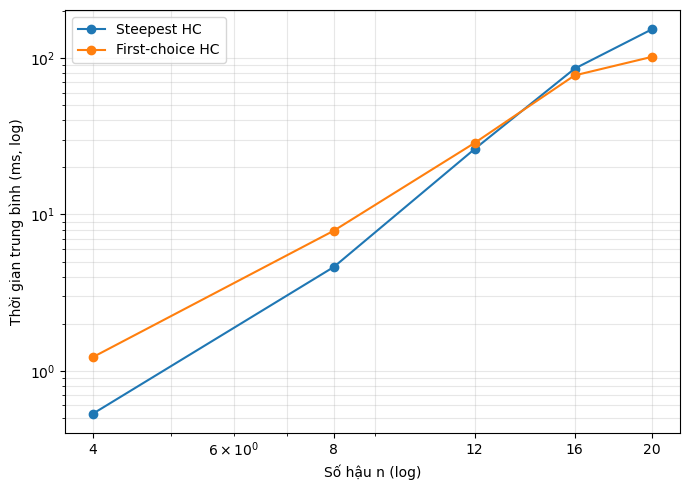

**Độ dốc thực nghiệm:** Steepest HC: p ≈ 3.62, First-choice HC: p ≈ 2.86. Ở n = 20, **First-choice HC** có thời gian chạy trung bình thấp hơn; tuy nhiên cần đối chiếu tỷ lệ giải thành công và f trung bình trước khi kết luận hiệu năng thực tế.

In [37]:
scaling_names = ['Steepest HC', 'First-choice HC']
print('Đang khảo sát mở rộng cho n = 12, 16, 20...')
for n in [12, 16, 20]:
    for trial in range(20):
        measure_queens(n, trial, scaling_names)

queen_all_results = pd.DataFrame(queen_records)
scaling_results = queen_all_results[
    queen_all_results['Thuật toán'].isin(scaling_names)
].copy()
# Với n = 4, 8 chỉ lấy 20 lần chạy đầu tiên của từng thuật toán để đảm bảo cân bằng mẫu 20 lượt
scaling_results = scaling_results.groupby(['n', 'Thuật toán'], sort=False).head(20)
scaling_summary = scaling_results.groupby(['n', 'Thuật toán'], sort=False).agg(
    thoi_gian_ms_TB=('ms', 'mean'),
    f_TB=('f', 'mean'),
    thanh_cong_phan_tram=('f', lambda values: 100 * (values == 0).mean()),
    danh_gia_TB=('Đánh giá', 'mean'),
)
display(scaling_summary.round(3))

plt.figure(figsize=(7, 5))
slopes = {}
for name in scaling_names:
    subset = scaling_summary.xs(name, level='Thuật toán').sort_index()
    plt.loglog(subset.index, subset.thoi_gian_ms_TB, 'o-', label=name)
    slopes[name] = np.polyfit(np.log(subset.index), np.log(subset.thoi_gian_ms_TB), 1)[0]
plt.xticks([4, 8, 12, 16, 20], ['4', '8', '12', '16', '20'])
plt.xlabel('Số hậu n (log)')
plt.ylabel('Thời gian trung bình (ms, log)')
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

largest = scaling_summary.loc[20]
fastest = largest.thoi_gian_ms_TB.idxmin()
display(Markdown(
    '**Độ dốc thực nghiệm:** ' + ', '.join(f'{name}: p ≈ {value:.2f}' for name, value in slopes.items())
    + f'. Ở n = 20, **{fastest}** có thời gian chạy trung bình thấp hơn; ' 
    'tuy nhiên cần đối chiếu tỷ lệ giải thành công và f trung bình trước khi kết luận hiệu năng thực tế.'
))


## Advanced task: Exploring other Local Moves Operators

So sánh First-choice Hill Climbing với hai toán tử chuyển dịch quân hậu trên $n = 8$ và $n = 12$ (mỗi cấu hình 30 lần chạy độc lập, cùng seed và tối đa 5.000 đánh giá):
1. **Chuyển hàng bất kỳ (`any`):** Dời hậu sang hàng bất kỳ trong cùng cột ($n(n-1)$ láng giềng).
2. **Dời hàng kề (`adjacent`):** Chỉ cho phép hậu di chuyển lên hoặc xuống 1 ô lân cận trong cùng cột ($n$ đến $2n$ láng giềng).

Toán tử di chuyển kề thu hẹp đáng kể không gian tìm kiếm mỗi bước, giúp giảm chi phí xét duyệt nhưng có nguy cơ làm thuật toán sớm mắc kẹt ở cực tiểu cục bộ hẹp.

In [38]:
operator_records = []
for n in [8, 12]:
    for trial in range(30):
        seed = 88000 + 100 * n + trial
        start = np.random.default_rng(seed).integers(0, n, size=n)
        for operator in ['any', 'adjacent']:
            started = perf_counter()
            run = queens_first_choice(start, max_evals=5000, seed=seed + 1, operator=operator)
            milliseconds = (perf_counter() - started) * 1000
            assert run['best_f'] == conflicts(run['best_board'])
            operator_records.append({'n': n, 'Toán tử': operator, 'f': run['best_f'],
                                     'ms': milliseconds, 'Đánh giá': run['evaluations']})

operator_summary = pd.DataFrame(operator_records).groupby(['n', 'Toán tử']).agg(
    f_TB=('f', 'mean'),
    thanh_cong_phan_tram=('f', lambda values: 100 * (values == 0).mean()),
    thoi_gian_ms_TB=('ms', 'mean'),
    danh_gia_TB=('Đánh giá', 'mean'),
)
display(operator_summary.round(3))


f_TB  thanh_cong_phan_tram  thoi_gian_ms_TB  danh_gia_TB
n  Toán tử                                                            
8  adjacent  3.567                 3.333            2.473       60.100
   any       1.400                10.000            7.797      216.700
12 adjacent  5.733                 0.000            5.061       97.967
   any       1.867                 6.667           24.349      541.433

### Tổng kết Task 6 (Bài 8)

- **Hội tụ:** SA cho chất lượng giải bài toán tốt nhất nhờ khả năng thoát bẫy cực tiểu địa phương. Steepest HC hội tụ nhanh ở số bước ít nhất nhưng xác suất kẹt cực tiểu cao nhất.
- **Khả năng mở rộng:** First-choice HC có chi phí mỗi bước $O(n)$ thấp hơn đáng kể so với Steepest HC $O(n^3)$ khi $n$ tăng, nhưng cả hai thuật toán tìm kiếm cục bộ thuần túy (không khởi động lại) đều giảm mạnh tỷ lệ giải thành công khi kích thước bài toán lớn.
- **Toán tử lân cận:** Toán tử dời hàng kề (`adjacent`) giúp giảm số lượng láng giềng cần xét, nhưng hạn chế biên độ di chuyển khiến thuật toán dễ rơi vào các cực tiểu nông không lối thoát hơn toán tử chuyển hàng bất kỳ (`any`).

## More Things to Do (not for credit)

- Khảo sát thêm các cấu trúc dữ liệu đếm xung đột $O(1)$ cập nhật theo từng nước đi.
- Thử nghiệm chiến lược kết hợp Random Restart với Simulated Annealing.
- Áp dụng giải thuật di truyền (Genetic Algorithm) kết hợp lai ghép hoán vị để so sánh toàn diện.